# Second-block-anchored merger — six blocks, dual T4, ten epochs

This is an updated copy of your uploaded notebook. **Start a fresh run:** previous averaging-based checkpoints are incompatible.

The merger generates **second-block weights + learned corrections**. Zero-initialized output heads make checkpoint zero exactly the drop-first baseline. Original GPT-2 stays frozen; all matrices, biases and LayerNorm vectors can receive corrections.

**Objective:** joint hidden normalized MSE + `1.0 × T² KL(original || compressed)` + `0.01 × normalized correction penalty`, with `T=2`. Ground-truth CE is logged but its training weight defaults to zero. These coefficients are starting settings, not experimentally optimized values.

Training mixes one through five nonoverlapping pair replacements in the actual student model. Each replacement is generated from original weights; no recursive merging occurs. Checkpoint selection gives equal weight to five compression levels and compares against matching drop-first baselines.

**GPU use:** select Kaggle **T4 ×2** and enable Internet. Batch auto-tuning benchmarks global batches 2, 4, 8 and 16 using five simultaneous merges, and selects the fastest safe candidate. Batch 16 means eight windows per GPU, versus one per GPU previously. Coalesced parameter/gradient transfers reduce inter-GPU transfer overhead. Memory allocation and compute utilization are different; no fixed utilization or speedup is promised.

**Budget:** ten corpus passes, subject to seven hours including startup checks, batch tuning and checkpoint validation. Final ranking/testing/export is additional. A larger batch means fewer optimizer updates per corpus pass.

**Evaluation:** WikiText-2 train articles only for learning/selection; full WikiText-2 official validation and 32,768-token external test samples from DBpedia-14, AG News and IMDb. All raw learned results and controls are retained. A separately labelled **guarded** model uses learned weights only if its whole-plan ranking-holdout CE improves on drop-first by at least 0.001; otherwise it uses drop-first. This is a held-out selection rule, not an unseen-domain guarantee.


In [1]:
%pip -q install transformers==4.51.3 "datasets>=3.5,<5" pandas matplotlib tqdm


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 33.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 30.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 78.8 MB/s eta 0:00:00:00:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires huggingface-hub<2.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
Note: you may need to restart the kernel to use updated packages.


## Implementation

In [2]:
"""Frozen GPT-2 -> learned two-block weight merger. Kaggle dual T4, anchored experiment v7.

Install in a fresh Kaggle GPU notebook (Internet ON), without replacing torch:
%pip -q install transformers==4.51.3 'datasets>=3.5,<5' pandas matplotlib tqdm

Run this file, or use the accompanying self-contained notebook. Only merger
parameters are optimized. Final test data never select checkpoints or pairs.
"""
# %% Imports and configuration
import os
os.environ.setdefault("USE_TF", "0")
os.environ.setdefault("USE_FLAX", "0")
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
import copy, gc, hashlib, itertools, json, math, random, time, warnings
from contextlib import contextmanager
from dataclasses import dataclass, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from torch.func import functional_call
from torch.utils.checkpoint import checkpoint
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages

VERSION = "wikitext2-anchored-merger-v7"

@dataclass
class Config:
    output_dir: str = "/kaggle/working/gpt2_anchored_merger_v7"
    model_id: str = "openai-community/gpt2"
    seed: int = 42
    epochs: int = 10
    training_hours: float = 7.0  # Training, validation and checkpoint saves; not final testing.
    train_seq_len: int = 256
    train_batch_size: int = 16  # Maximum GLOBAL batch; measured auto-tuning selects <= this.
    learning_rate: float = 1e-4
    weight_decay: float = 0.01
    clip_grad: float = 1.0
    ce_weight: float = 0.0  # Optional ground-truth CE; disabled for the preservation experiment.
    kd_weight: float = 1.0
    correction_weight: float = 0.01
    temperature: float = 2.0
    logit_chunk_tokens: int = 128
    auto_tune_batch: bool = True
    peak_memory_fraction: float = 0.85
    accept_margin_ce: float = 0.001
    merger_width: int = 384
    merger_heads: int = 6
    merger_blocks: int = 6
    merger_ff_multiplier: int = 4
    checkpoint_fraction: float = 0.05
    ranking_fraction: float = 0.05
    checkpoint_tokens: int = 4096
    ranking_tokens: int = 16384
    validation_interval_minutes: float = 30.0
    save_every_steps: int = 200
    eval_context: int = 512
    eval_stride: int = 256
    external_test_tokens: int = 32768  # Per dataset; set to None for full test splits.
    wikitext_validation_tokens: int = None  # Full official validation by default.
    export_models: bool = True  # Five selected learned models, approximately 2 GB total.
    resume: bool = True

def atomic_json(value, path):
    path = Path(path); tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(value, indent=2, allow_nan=False), encoding="utf-8")
    tmp.replace(path)

def atomic_torch(value, path):
    path = Path(path); tmp = path.with_suffix(path.suffix + ".tmp")
    torch.save(value, tmp); tmp.replace(path)

def tensor_hash(tensor):
    return hashlib.sha256(tensor.detach().cpu().contiguous().numpy().tobytes()).hexdigest()

def module_hash(module):
    digest = hashlib.sha256()
    for name, p in module.named_parameters():
        digest.update(name.encode()); digest.update(p.detach().cpu().contiguous().numpy().tobytes())
    return digest.hexdigest()

def cpu_state(module):
    return {k: v.detach().cpu().clone() for k, v in module.state_dict().items()}

def pair_name(i):
    return f"L{i+1}-L{i+2}"

def exp_metric(value):
    if not math.isfinite(value) or value > 700:
        raise FloatingPointError("CE/log-ratio is non-finite or too large to report reliably; no PPL clipping is performed.")
    return math.exp(value)

def ppl_change(student_ce, original_ce):
    gap = student_ce-original_ce
    exp_metric(gap)  # Explicitly reject overflow instead of fabricating a capped metric.
    return 100*math.expm1(gap)

def epoch_plan(seed, epoch, windows, batch_size):
    order = np.random.default_rng(seed+epoch).permutation(windows)
    batches = math.ceil(windows/batch_size)
    rng = np.random.default_rng(seed+10000+epoch)
    pairs = np.concatenate([rng.permutation(11) for _ in range(math.ceil(batches/11))])[:batches]
    return order, pairs

def compatible_selection(costs, k):
    """Exact minimum additive single-pair cost for k nonoverlapping edges.
    This is NOT a claim to minimize the jointly merged model's actual PPL.
    """
    candidates = (p for p in itertools.combinations(range(len(costs)), k)
                  if all(b > a + 1 for a, b in zip(p, p[1:])))
    return min(candidates, key=lambda p: (sum(costs[i] for i in p), p))

def evaluation_spans(n, context, stride):
    if not 1 <= stride < context:
        raise ValueError("Require 1 <= eval_stride < eval_context.")
    previous_end = 0
    for begin in range(0, n, stride):
        end = min(begin + context, n)
        first = max(1, end - begin - (end - previous_end))
        yield begin, end, first
        previous_end = end
        if end == n:
            break

def article_documents(rows):
    """WikiText raw rows -> whole articles, before any train/holdout split."""
    documents, current = [], []
    for row in rows:
        s = row["text"].strip()
        heading = s.startswith("= ") and s.endswith(" =") and s.count("=") == 2
        if heading and current:
            documents.append("\n".join(current)); current = []
        if s:
            current.append(row["text"].rstrip())
    if current:
        documents.append("\n".join(current))
    return documents

def split_articles(documents, seed, checkpoint_fraction, ranking_fraction):
    # Exact duplicate articles cannot cross partitions.
    unique = list(dict.fromkeys(documents))
    order = np.random.default_rng(seed).permutation(len(unique)).tolist()
    nv = max(1, int(len(unique) * checkpoint_fraction))
    nr = max(1, int(len(unique) * ranking_fraction))
    if nv + nr >= len(unique):
        raise ValueError("Too few independent articles for three partitions.")
    groups = {"checkpoint": order[:nv], "ranking": order[nv:nv+nr], "train": order[nv+nr:]}
    return {k: [unique[i] for i in v] for k, v in groups.items()}, {
        k: [hashlib.sha256(unique[i].encode()).hexdigest() for i in v] for k, v in groups.items()}

# %% Weight tokenization and nonlinear merger
# GPT-2 Conv1D weights use [input, output], unlike nn.Linear.
FAMILIES = [
    ("q_w", "square", (768, 768)), ("k_w", "square", (768, 768)),
    ("v_w", "square", (768, 768)), ("o_w", "square", (768, 768)),
    ("up_w", "up", (768, 3072)), ("down_w", "down", (3072, 768)),
    ("q_b", "vector", (768,)), ("k_b", "vector", (768,)),
    ("v_b", "vector", (768,)), ("o_b", "vector", (768,)),
    ("up_b", "vector", (3072,)), ("down_b", "vector", (768,)),
    ("ln1_w", "vector", (768,)), ("ln1_b", "vector", (768,)),
    ("ln2_w", "vector", (768,)), ("ln2_b", "vector", (768,)),
]
PATCH = {"square": (64, 64), "up": (64, 256), "down": (256, 64), "vector": (64,)}

def families_from_block(block):
    return families_from_parameters(dict(block.named_parameters()))

def families_from_parameters(p):
    q, k, v = p["attn.c_attn.weight"].split(768, dim=1)
    qb, kb, vb = p["attn.c_attn.bias"].split(768)
    return dict(q_w=q, k_w=k, v_w=v, o_w=p["attn.c_proj.weight"],
        up_w=p["mlp.c_fc.weight"], down_w=p["mlp.c_proj.weight"],
        q_b=qb, k_b=kb, v_b=vb, o_b=p["attn.c_proj.bias"],
        up_b=p["mlp.c_fc.bias"], down_b=p["mlp.c_proj.bias"],
        ln1_w=p["ln_1.weight"], ln1_b=p["ln_1.bias"],
        ln2_w=p["ln_2.weight"], ln2_b=p["ln_2.bias"])

def pack(x, kind):
    patch = PATCH[kind]
    if kind == "vector":
        return x.reshape(-1, patch[0])
    ph, pw = patch; h, w = x.shape
    return x.reshape(h//ph, ph, w//pw, pw).permute(0, 2, 1, 3).reshape(-1, ph*pw)

def unpack(x, kind, shape):
    if kind == "vector":
        return x.reshape(shape)
    ph, pw = PATCH[kind]; h, w = shape
    return x.reshape(h//ph, w//pw, ph, pw).permute(0, 2, 1, 3).reshape(shape)

def block_parameters(f):
    return {
        "attn.c_attn.weight": torch.cat([f["q_w"], f["k_w"], f["v_w"]], dim=1),
        "attn.c_attn.bias": torch.cat([f["q_b"], f["k_b"], f["v_b"]]),
        "attn.c_proj.weight": f["o_w"], "attn.c_proj.bias": f["o_b"],
        "mlp.c_fc.weight": f["up_w"], "mlp.c_fc.bias": f["up_b"],
        "mlp.c_proj.weight": f["down_w"], "mlp.c_proj.bias": f["down_b"],
        "ln_1.weight": f["ln1_w"], "ln_1.bias": f["ln1_b"],
        "ln_2.weight": f["ln2_w"], "ln_2.bias": f["ln2_b"],
    }

class WeightAttentionBlock(nn.Module):
    """One unmasked, bidirectional, pre-LN transformer block over weight patches."""
    def __init__(self, width, heads, multiplier):
        super().__init__(); self.heads = heads
        self.ln1 = nn.LayerNorm(width); self.qkv = nn.Linear(width, 3*width)
        self.out = nn.Linear(width, width); self.ln2 = nn.LayerNorm(width)
        self.ff = nn.Sequential(nn.Linear(width, multiplier*width), nn.GELU(),
                                nn.Linear(multiplier*width, width))

    def forward(self, x):
        b, n, d = x.shape
        q, k, v = self.qkv(self.ln1(x)).reshape(b, n, 3, self.heads, d//self.heads).permute(2,0,3,1,4).unbind(0)
        y = F.scaled_dot_product_attention(q, k, v, dropout_p=0.0, is_causal=False)
        x = x + self.out(y.transpose(1,2).reshape(b,n,d))
        return x + self.ff(self.ln2(x))

class PairWeightMerger(nn.Module):
    def __init__(self, cfg):
        super().__init__(); d = cfg.merger_width
        if d % cfg.merger_heads:
            raise ValueError("Merger width must be divisible by head count.")
        self.enc = nn.ModuleDict({k: nn.Linear(math.prod(s), d) for k, s in PATCH.items()})
        self.dec = nn.ModuleDict({k: nn.Linear(d, math.prod(s)) for k, s in PATCH.items()})
        self.family = nn.Embedding(len(FAMILIES), d)
        self.source = nn.Embedding(2, d); self.layer = nn.Embedding(12, d)
        self.row = nn.Embedding(48, d); self.col = nn.Embedding(48, d)
        self.blocks = nn.Sequential(*[WeightAttentionBlock(d, cfg.merger_heads, cfg.merger_ff_multiplier)
                                      for _ in range(cfg.merger_blocks)])
        self.fuse = nn.Sequential(nn.LayerNorm(2*d), nn.Linear(2*d, d), nn.GELU())
        # Exactly drop-first at initialization; every second-block tensor can receive a learned correction.
        for head in self.dec.values():
            nn.init.zeros_(head.weight); nn.init.zeros_(head.bias)

    def forward(self, a, b, left_layer):
        scale, patches, chunks, sizes = {}, [{}, {}], [[], []], []
        for f_id, (name, kind, shape) in enumerate(FAMILIES):
            scale[name] = torch.sqrt((a[name].float().square().mean()+b[name].float().square().mean())/2).clamp_min(0.01)
            count = math.prod(shape)//math.prod(PATCH[kind]); sizes.append(count)
            idx = torch.arange(count, device=a[name].device)
            columns = 1 if kind == "vector" else shape[1]//PATCH[kind][1]
            position = self.row(idx//columns) + self.col(idx%columns) + self.family.weight[f_id]
            for source_id, f in enumerate((a, b)):
                patches[source_id][name] = pack(f[name], kind)
                x = self.enc[kind](patches[source_id][name]/scale[name])
                chunks[source_id].append(x + position + self.source.weight[source_id] + self.layer.weight[left_layer+source_id])
        # Entire first block, then entire second block. 1020 + 1020 tokens.
        x = torch.cat([torch.cat(c, dim=0) for c in chunks], dim=0).unsqueeze(0)
        z = self.blocks(x).squeeze(0)
        za, zb = z.chunk(2, dim=0); fused = self.fuse(torch.cat([za, zb], dim=-1))
        outputs = {}; offset = 0
        for (name, kind, shape), count in zip(FAMILIES, sizes):
            delta = self.dec[kind](fused[offset:offset+count]).float() * scale[name]
            merged = patches[1][name] + delta
            outputs[name] = unpack(merged, kind, shape); offset += count
        return block_parameters(outputs)

# %% Dataset preparation, frozen teacher, and correct token-level evaluation
class Experiment:
    def __init__(self, cfg):
        self.cfg = cfg; self.out = Path(cfg.output_dir); self.out.mkdir(parents=True, exist_ok=True)
        if not torch.cuda.is_available():
            raise RuntimeError("Select Kaggle Settings > Accelerator > GPU T4 and rerun.")
        if cfg.epochs < 1 or cfg.training_hours <= 0 or not 0 < cfg.checkpoint_fraction + cfg.ranking_fraction < 1:
            raise ValueError("Invalid epoch/time/split configuration.")
        if not 2 <= cfg.train_seq_len <= 1024 or not 2 <= cfg.eval_context <= 1024:
            raise ValueError("GPT-2 context lengths must be in [2, 1024].")
        if not 1 <= cfg.eval_stride < cfg.eval_context:
            raise ValueError("Evaluation stride must be smaller than context.")
        random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed); torch.cuda.manual_seed_all(cfg.seed)
        self.device = torch.device("cuda:0")  # Primary GPU; training subclass also uses cuda:1.
        print("GPU:", torch.cuda.get_device_name(0), "| torch", torch.__version__)
        self.tokenizer = AutoTokenizer.from_pretrained(cfg.model_id)
        self.model = AutoModelForCausalLM.from_pretrained(cfg.model_id, torch_dtype=torch.float32,
                                                         attn_implementation="eager").to(self.device)
        self.model.eval().requires_grad_(False); self.model.config.use_cache = False
        assert self.model.config.n_layer == 12 and self.model.config.n_embd == 768, "This tokenizer supports GPT-2 Small only."
        self.original_blocks = tuple(self.model.transformer.h)
        self.original_hash = module_hash(self.model)
        self.original_parameters = sum(p.numel() for p in self.model.parameters())
        self.block_parameters = sum(p.numel() for p in self.original_blocks[0].parameters())
        self.sources = tuple({k:v.detach() for k,v in families_from_block(b).items()} for b in self.original_blocks)
        self.merger = PairWeightMerger(cfg).to(self.device)
        self.optimizer = torch.optim.AdamW(self.merger.parameters(), lr=cfg.learning_rate, weight_decay=cfg.weight_decay)
        self.scaler = torch.amp.GradScaler("cuda")
        self.prepare_training_data()
        self.signature = hashlib.sha256(json.dumps(self.manifest, sort_keys=True).encode()).hexdigest()
        self.training_log = []; self.validation_log = []
        self.state = dict(epoch=0, cursor=0, step=0, seconds=0., presentations=0, best=float("inf"),
                          pair_updates=[0]*11, last_validation=0., validation_seconds=120.)
        print("Original parameters:", f"{self.original_parameters:,}", "| merger parameters:",
              f"{sum(p.numel() for p in self.merger.parameters()):,}")
        print("Weight tokens: 2 x 1020 = 2040; all matrices, biases and LayerNorm vectors are generated.")

    def autocast(self, enabled=True):
        return torch.autocast("cuda", dtype=torch.float16, enabled=enabled)

    def encode_documents(self, documents, limit=None):
        ids = []
        for doc in documents:
            ids.extend(self.tokenizer.encode(doc, add_special_tokens=False, truncation=False))
            ids.append(self.tokenizer.eos_token_id)
            if limit is not None and len(ids) >= limit:
                ids = ids[:limit]; break
        if len(ids) < 2:
            raise ValueError("A token partition is empty.")
        return torch.tensor(ids, dtype=torch.long)

    def prepare_training_data(self):
        cfg = self.cfg
        ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="train")
        articles = article_documents(ds)
        partitions, hashes = split_articles(articles, cfg.seed, cfg.checkpoint_fraction, cfg.ranking_fraction)
        self.train_ids = self.encode_documents(partitions["train"])
        self.val_ids = self.encode_documents(partitions["checkpoint"], cfg.checkpoint_tokens)
        self.rank_ids = self.encode_documents(partitions["ranking"], cfg.ranking_tokens)
        n = len(self.train_ids)//cfg.train_seq_len
        if n < cfg.train_batch_size:
            raise ValueError("Insufficient training windows.")
        self.windows = self.train_ids[:n*cfg.train_seq_len].reshape(n, cfg.train_seq_len)
        self.manifest = dict(version=VERSION, config=asdict(cfg), original_sha256=self.original_hash,
            train_dataset="Salesforce/wikitext:wikitext-2-raw-v1:train", fingerprint=ds._fingerprint,
            article_hashes=hashes, removed_exact_duplicate_articles=len(articles)-sum(map(len, partitions.values())),
            token_hashes={"train":tensor_hash(self.train_ids), "checkpoint":tensor_hash(self.val_ids), "ranking":tensor_hash(self.rank_ids)},
            tokens={"train_available":len(self.train_ids), "train_per_epoch":self.windows.numel(),
                    "dropped_train_tail":len(self.train_ids)-self.windows.numel(), "checkpoint":len(self.val_ids), "ranking":len(self.rank_ids)},
            objective="joint hidden NMSE + KD_weight*T^2*KL(original||student) + correction_weight*relative_delta_MSE + optional_CE",
            dependencies={"torch":torch.__version__, "transformers":__import__("transformers").__version__, "datasets":__import__("datasets").__version__})
        path = self.out/"manifest.json"
        if path.exists() and json.loads(path.read_text(encoding="utf-8")) != self.manifest:
            raise RuntimeError("Output folder belongs to different settings/data. Choose a NEW output_dir.")
        atomic_json(self.manifest, path)
        print("Data:", self.manifest["tokens"], "| each epoch traverses the entire retained training partition once.")

    @contextmanager
    def use_blocks(self, blocks):
        old = self.model.transformer.h; old_n = self.model.config.n_layer
        self.model.transformer.h = nn.ModuleList(blocks); self.model.config.n_layer = len(blocks)
        try:
            yield
        finally:
            self.model.transformer.h = old; self.model.config.n_layer = old_n

    def parameters_for(self, pair, use_checkpoint=False):
        if use_checkpoint:
            # Non-reentrant checkpoint supports frozen inputs and trainable captured parameters.
            return checkpoint(lambda: self.merger(self.sources[pair], self.sources[pair+1], pair), use_reentrant=False)
        return self.merger(self.sources[pair], self.sources[pair+1], pair)

    def replacement(self, pair, method="learned"):
        with torch.no_grad(), self.autocast():
            if method == "learned":
                if hasattr(self, "frozen_pair_weights"):
                    p = self.frozen_pair_weights[pair]
                else:
                    p = self.parameters_for(pair)
            elif method == "average":
                a, b = map(lambda m:dict(m.named_parameters()), self.original_blocks[pair:pair+2])
                p = {k:(a[k]+b[k])/2 for k in a}
            elif method in ("drop_first", "drop_second"):
                return self.original_blocks[pair + (method == "drop_first")]
            else:
                raise ValueError(method)
            block = copy.deepcopy(self.original_blocks[pair+1])
            keys = set(dict(block.named_parameters()))
            assert set(p) == keys, "Incomplete generated parameters."
            for k, target in block.named_parameters():
                assert target.shape == p[k].shape, (k, target.shape, p[k].shape)
                target.copy_(p[k])
            return block.eval().requires_grad_(False)

    def variant(self, pairs, method="learned"):
        pairs = tuple(sorted(pairs))
        if any(not 0 <= p < 11 for p in pairs) or any(b <= a+1 for a,b in zip(pairs,pairs[1:])):
            raise ValueError("Pairs must be valid and nonoverlapping.")
        blocks = []; i = 0
        while i < 12:
            if i in pairs:
                blocks.append(self.replacement(i, method)); i += 2
            else:
                blocks.append(self.original_blocks[i]); i += 1
        assert len(blocks) == 12-len(pairs)
        return blocks

    @torch.inference_mode()
    def score(self, ids):
        total = 0.; count = top1 = top5 = 0
        for begin, end, first in evaluation_spans(len(ids), self.cfg.eval_context, self.cfg.eval_stride):
            batch = ids[begin:end].unsqueeze(0).to(self.device)
            with self.autocast():
                h = self.model.transformer(batch, use_cache=False, return_dict=True).last_hidden_state[0]
                for pos in range(first, end-begin, 64):
                    stop = min(pos+64, end-begin)
                    logits = self.model.lm_head(h[pos-1:stop-1]).float()
                    labels = batch[0,pos:stop]
                    nll = F.cross_entropy(logits, labels, reduction="sum")
                    if not torch.isfinite(nll):
                        raise FloatingPointError("Non-finite evaluation loss; model is unstable.")
                    total += float(nll); indices = logits.topk(5,dim=-1).indices
                    top1 += int((indices[:,0] == labels).sum())
                    top5 += int((indices == labels[:,None]).any(dim=-1).sum()); count += len(labels)
        assert count == len(ids)-1, (count, len(ids))
        ce = total/count
        return dict(ce=ce, ppl=exp_metric(ce), top1_accuracy=top1/count, top5_accuracy=top5/count, scored_tokens=count)

    def ce(self, hidden, ids, differentiable):
        # Chunked vocabulary projections + checkpointed CE avoid retaining a huge logits tensor.
        terms = []
        for start in range(0, ids.shape[1]-1, 64):
            end = min(start+64, ids.shape[1]-1)
            h = hidden[:,start:end]; labels = ids[:,start+1:end+1]
            def chunk_loss(x, y):
                logits = self.model.lm_head(x).float()
                return F.cross_entropy(logits.reshape(-1, logits.shape[-1]), y.reshape(-1), reduction="sum")
            terms.append(checkpoint(chunk_loss, h, labels, use_reentrant=False) if differentiable else chunk_loss(h,labels))
        return torch.stack(terms).sum()/(ids.shape[0]*(ids.shape[1]-1))



# %% Resume checkpoint helpers
    def save_resume(self, clock_start=None, elapsed_base=None):
        if clock_start is not None:
            self.state["seconds"] = elapsed_base + time.monotonic()-clock_start
        atomic_torch(dict(signature=self.signature, merger=cpu_state(self.merger), optimizer=self.optimizer.state_dict(),
                          scaler=self.scaler.state_dict(), state=self.state, training_log=self.training_log,
                          validation_log=self.validation_log, cpu_rng=torch.get_rng_state(), cuda_rng=torch.cuda.get_rng_state_all()),
                     self.out/"resume.pt")
        pd.DataFrame(self.training_log).to_csv(self.out/"training_log.csv",index=False)
        pd.DataFrame(self.validation_log).to_csv(self.out/"validation_history.csv",index=False)

    def restore(self):
        path = self.out/"resume.pt"
        if self.cfg.resume and path.exists():
            # Only load this experiment's own trusted checkpoint, never an arbitrary downloaded pickle.
            saved = torch.load(path,map_location="cpu",weights_only=False)
            assert saved["signature"] == self.signature, "Checkpoint mismatch."
            self.merger.load_state_dict(saved["merger"]); self.optimizer.load_state_dict(saved["optimizer"])
            self.scaler.load_state_dict(saved["scaler"]); self.state = saved["state"]
            self.training_log = saved["training_log"]; self.validation_log = saved["validation_log"]
            torch.set_rng_state(saved["cpu_rng"]); torch.cuda.set_rng_state_all(saved["cuda_rng"])
            print("Resumed:", self.state)
            return True
        return False



# %% Frozen-merger evaluation, compatible multi-pair selection, and model export
    def prepare_tests(self):
        cfg = self.cfg
        wt = load_dataset("Salesforce/wikitext","wikitext-2-raw-v1",split="validation")
        sets = {"WikiText2_validation":self.encode_documents(article_documents(wt),cfg.wikitext_validation_tokens)}
        fingerprints = {"WikiText2_validation":wt._fingerprint}
        specifications = [("DBpedia14","fancyzhx/dbpedia_14",lambda r:r["title"]+"\n"+r["content"]),
                          ("AG_News","fancyzhx/ag_news",lambda r:r["text"]),
                          ("IMDb","stanfordnlp/imdb",lambda r:r["text"])]
        for name, dataset, format_text in specifications:
            ds = load_dataset(dataset,split="test").shuffle(seed=cfg.seed)
            sets[name] = self.encode_documents((format_text(r) for r in ds),cfg.external_test_tokens)
            fingerprints[name] = ds._fingerprint
        manifest = {k:dict(tokens=len(v),sha256=tensor_hash(v),fingerprint=fingerprints[k]) for k,v in sets.items()}
        path = self.out/"test_manifest.json"
        if path.exists():
            assert json.loads(path.read_text()) == manifest, "Test data changed; use a fresh output folder."
        atomic_json(manifest,path)
        return sets


# %% Tables and charts: PDF, PNGs, CSV, and a factual Markdown report
    def make_reports(self, results, ranking, selections):
        figures = self.out/"charts"; figures.mkdir(exist_ok=True)
        datasets = list(results.dataset.unique()); methods = ["learned","guarded","average","drop_first","drop_second"]
        plt.rcParams.update({"figure.dpi":120,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
        with PdfPages(self.out/"experiment_charts.pdf") as pdf:
            def save(fig,name):
                fig.tight_layout(); pdf.savefig(fig,bbox_inches="tight"); fig.savefig(figures/f"{name}.png",bbox_inches="tight"); plt.close(fig)
            single = results[(results.stage=="single") & (results.method=="learned")]
            data = single.pivot(index="pairs",columns="dataset",values="ppl_increase_pct").reindex([pair_name(i) for i in range(11)])[datasets]
            fig,ax = plt.subplots(figsize=(10,7)); values = data.to_numpy()
            image = ax.imshow(values,aspect="auto",cmap="YlOrRd")
            ax.set_xticks(range(len(datasets)),datasets); ax.set_yticks(range(11),data.index)
            for i in range(11):
                for j in range(len(datasets)):
                    ax.text(j,i,f"{values[i,j]:.1f}%",ha="center",va="center",fontsize=9)
            ax.set_title("Learned single-pair merges: PPL change versus original GPT-2\nLower is better; final test datasets do not determine ranking")
            fig.colorbar(image,ax=ax,label="PPL change (%)"); save(fig,"single_pair_heatmap")
            fig,axes = plt.subplots(2,2,figsize=(13,9))
            for ax,dataset in zip(axes.flat,datasets):
                for method in methods:
                    frame = results[(results.stage=="single")&(results.dataset==dataset)&(results.method==method)].set_index("pairs").reindex([pair_name(i) for i in range(11)])
                    ax.plot(range(1,12),frame.ppl,marker=".",label=method)
                original = results[(results.stage=="original")&(results.dataset==dataset)].ppl.iloc[0]
                ax.axhline(original,color="black",ls="--",label="original")
                ax.set(title=dataset,xlabel="Left layer of pair",ylabel="PPL (log scale)",yscale="log",xticks=range(1,12))
                ax.grid(alpha=.2); ax.legend(fontsize=8)
            save(fig,"single_pairs_controls")
            fig,axes = plt.subplots(2,2,figsize=(13,9))
            for ax,dataset in zip(axes.flat,datasets):
                original = results[(results.stage=="original")&(results.dataset==dataset)].ppl.iloc[0]
                for method in methods:
                    frame = results[(results.stage=="selected")&(results.dataset==dataset)&(results.method==method)].sort_values("merges")
                    ax.plot([0]+frame.parameter_reduction_pct.tolist(),[1]+(frame.ppl/original).tolist(),marker="o",label=method)
                ax.set(title=dataset,xlabel="Total model parameters removed (%)",ylabel="PPL / original PPL (log scale)",yscale="log")
                ax.grid(alpha=.2); ax.legend(fontsize=8)
            save(fig,"compression_quality_tradeoff")
            fig,axes = plt.subplots(1,2,figsize=(12,4.5))
            for ax,metric in zip(axes,["top1_accuracy","top5_accuracy"]):
                for dataset in datasets:
                    frame = results[(results.stage.isin(["original","selected"]))&(results.dataset==dataset)&(results.method.isin(["original","learned"]))].sort_values("merges")
                    ax.plot(frame.merges,100*frame[metric],marker="o",label=dataset)
                ax.set(xlabel="Nonoverlapping pair merges",ylabel=metric+" (%)",xticks=range(6)); ax.legend(fontsize=8); ax.grid(alpha=.2)
            save(fig,"next_token_accuracy")
            if self.training_log:
                log = pd.DataFrame(self.training_log); val = pd.DataFrame(self.validation_log)
                fig,axes = plt.subplots(1,3,figsize=(15,4.5))
                for column in ["hidden_loss","distillation_loss","correction_loss","loss"]:
                    axes[0].plot(log.epoch_fraction,log[column].rolling(50,min_periods=1).mean(),label=column)
                axes[0].set(xlabel="Corpus passes",ylabel="50-update rolling average",title="Training objective components"); axes[0].legend()
                axes[1].plot(val.epoch_fraction,val.mean_pair_ce,marker="o")
                axes[1].set(xlabel="Corpus passes",ylabel="Mean CE over all 11 pairs",title="Checkpoint holdout (lower is better)")
                axes[2].bar(range(1,12),self.state["pair_updates"])
                axes[2].set(xlabel="Left layer of pair",ylabel="Successful updates",title="Training coverage",xticks=range(1,12))
                save(fig,"training_and_validation")
            fig,ax = plt.subplots(figsize=(12,4.5))
            for k,pairs in selections.items():
                for layer in range(12):
                    merged = any(layer in (p,p+1) for p in pairs)
                    ax.add_patch(plt.Rectangle((layer+.04,k-.32),.92,.64,color="#a6c8ed" if merged else "#e3e3e3"))
                    ax.text(layer+.5,k,f"L{layer+1}",ha="center",va="center")
                for p in pairs:
                    ax.plot([p+.5,p+1.5],[k+.38,k+.38],lw=3,color="#194f88")
            ax.set(xlim=(0,12),ylim=(.4,5.6),yticks=range(1,6),ylabel="Number of pair merges",xticks=[],
                   title="Chosen compatible pairs: each set is selected independently from original blocks")
            save(fig,"selected_pair_layout")
            # Readable numerical summary tables, one page per dataset.
            for dataset in datasets:
                table = results[(results.dataset==dataset)&(results.stage.isin(["original","selected"]))&results.method.isin(["original","learned"])].sort_values("merges")
                cells = [[int(r.merges),int(r.blocks),r.pairs or "Original",f"{r.ppl:.3f}",f"{r.ppl_increase_pct:+.2f}%",f"{r.parameter_reduction_pct:.2f}%"] for r in table.itertuples()]
                fig,ax = plt.subplots(figsize=(12,4)); ax.axis("off"); ax.set_title(dataset+": selected learned models",pad=18)
                t = ax.table(cellText=cells,colLabels=["Merges","Blocks","Pairs","PPL","PPL change","Parameters removed"],loc="center",colWidths=[.07,.07,.4,.12,.15,.19])
                t.auto_set_font_size(False); t.set_fontsize(9); t.scale(1,1.9); save(fig,"table_"+dataset)
        audit = json.loads((self.out/"final_audit.json").read_text()); training = json.loads((self.out/"training_complete.json").read_text())
        text = ["# Frozen GPT-2 nonlinear pair-merger experiment", "", f"Version: {VERSION}",
            f"Training completed {training['epoch_fraction']:.3f} of {self.cfg.epochs} requested corpus passes in {training['training_seconds']/3600:.2f} hours; stop reason: {training['stopped_by']}.",
            f"Selected checkpoint: update {audit['selected_checkpoint']['step']}, corpus pass {audit['selected_checkpoint']['epoch_fraction']:.3f}. Update zero means drop-first initialization remained best under the joint checkpoint criterion.",
            "", "## Architecture and objective", "Original GPT-2 Small: 12 blocks, frozen throughout. Merger input: 2,040 weight-patch/vector-chunk tokens, ordered block A then block B. Learned family, coordinate, source-order and layer embeddings; unmasked bidirectional transformer; matched-patch fusion; shape-specific decoders generate corrections to every original SECOND-block matrix and vector; zero corrections exactly reproduce drop-first.",
            f"Merger: {self.cfg.merger_blocks} block(s), width {self.cfg.merger_width}, {self.cfg.merger_heads} heads; {audit['merger_parameters']:,} additional training-side parameters.",
            "Loss = joint hidden normalized MSE + temperature-scaled teacher-to-student KL + family-normalized correction penalty. Ground-truth CE has zero weight by default. Hidden targets come from the original full teacher, including the raw final-block output before ln_f. Weight and hidden preservation do not guarantee out-of-domain generalization.",
            "", "## Parameter accounting", f"Original: {self.original_parameters:,}; each removed block: {self.block_parameters:,}. Five pair merges remove {5*self.block_parameters:,} parameters ({500*self.block_parameters/self.original_parameters:.2f}%). Embeddings and LM head are retained and tied parameters counted once.",
            "The merger is a company-side model-generation tool. Exported client models contain only the compressed GPT-2 weights and tokenizer. Merger overhead is not counted as client savings; training and generation still incur that overhead. Parameter reduction is not a measured inference speedup.",
            "", "## Evaluation and selection", "Training articles, checkpoint articles and ranking articles are disjoint subsets of WikiText-2 TRAIN, split before tokenization. Official WikiText-2 validation and external official test splits are final evaluation only. External test token caps and hashes are in test_manifest.json. Labels are ignored. Documents are EOS separated; every evaluated next token is counted once under the same sliding-window settings.",
            "Single pairs are ranked by GUARDED PPL on the separate ranking holdout; raw learned and drop-first scores are also reported. For each k, exhaustive compatible-set search minimizes the SUM of guarded single-pair PPL percentage changes. This avoids overlapping layers and greedy dead ends, but does not guarantee the best joint PPL. Joint models are measured independently. Different k selections need not be nested. All replacements come from the original pretrained blocks.",
            "", "## Results", "See all_results.csv, pair_ranking.csv, single_pair_results.csv, multi_pair_results.csv, selected_compatible_pairs.csv and experiment_charts.pdf.",
            "```",results[(results.stage.isin(["original","selected"]))&results.method.isin(["original","learned"])][["dataset","merges","ppl","ppl_increase_pct","parameter_reduction_pct"]].to_string(index=False),"```",
            "", "## Interpretation limits", "Do not infer success from reconstruction loss alone: compare held-out PPL and controls. Arithmetic averaging and dropping either block are tested on the same pairs and text. This experiment adapts a merger to one fixed GPT-2 checkpoint; it does not establish transfer to unseen checkpoints. Accuracy is next TOKEN (BPE), not whole-word accuracy. Ten target passes mix single and simultaneous nonoverlapping merge tasks; they are not ten complete passes per pair. Test-domain PPLs are not directly comparable to one another. Runtime depends on the assigned GPU; completed passes and token presentations are reported, not assumed.",
            "", "Original and frozen-merger parameter hashes were checked after evaluation. gpu_preflight.json records the startup gradient checks."]
        (self.out/"REPORT.md").write_text("\n\n".join(text),encoding="utf-8")
        print("Saved tables, charts PDF, client models and report to",self.out)


# %% Explicit synchronous two-GPU training



# %% Anchored preservation objective and joint merge tasks
def valid_plan(pairs):
    pairs = tuple(sorted(pairs))
    if not pairs or any(p < 0 or p > 10 for p in pairs) or any(b <= a+1 for a,b in zip(pairs,pairs[1:])):
        raise ValueError('Expected nonempty, nonoverlapping original adjacent pairs.')
    return pairs

def plan_key(pairs):
    return ','.join(map(str, valid_plan(pairs)))

def plans_of_size(k):
    return tuple(p for p in itertools.combinations(range(11),k) if all(b>a+1 for a,b in zip(p,p[1:])))

PLAN_POOLS = {k:plans_of_size(k) for k in range(1,6)}

def task_for_batch(seed, epoch, batch_index):
    # One third single tasks, two thirds joint tasks. Single tasks cycle all 11 pairs.
    k = (1,1,2,3,4,5)[batch_index % 6]
    if k == 1:
        index = (batch_index//6)*2 + batch_index%6
        order = np.random.default_rng(seed+epoch*100003+index//11).permutation(11)
        return (int(order[index%11]),)
    rng = np.random.default_rng(seed+epoch*1000003+batch_index)
    return PLAN_POOLS[k][int(rng.integers(len(PLAN_POOLS[k])))]

def checkpoint_plans():
    # Fixed before training: all singles, plus two plans for every joint compression level.
    result = [(i,) for i in range(11)]
    for k in range(2,6):
        result += [tuple(range(0,2*k,2)), tuple(range(1,2*k+1,2))]
    return result

def guard_accept(learned_ce, drop_ce, margin):
    return bool(math.isfinite(learned_ce) and learned_ce <= drop_ce-margin)

def choose_batch(rows, fraction):
    eligible = [r for r in rows if r['status']=='ok' and max(r['gpu0_peak_fraction'],r['gpu1_peak_fraction']) <= fraction]
    if not eligible:
        raise RuntimeError('No safe measured batch. Reduce sequence length in a new run or inspect GPU memory users.')
    return int(max(eligible,key=lambda r:(r['tokens_per_second'],r['global_batch']))['global_batch'])

class PreservationWorker(nn.Module):
    def __init__(self, runner):
        super().__init__(); self.runner = runner

    def forward(self, ids, pairs):
        with torch.cuda.device(self.runner.device), self.runner.autocast():
            loss, logs, _ = self.runner.training_loss(ids,pairs)
        return loss, logs


class AnchoredExperiment(Experiment):
    def __init__(self, cfg):
        if torch.cuda.device_count() < 2:
            raise RuntimeError('Select Kaggle GPU T4 x2. This experiment requires two visible GPUs.')
        if cfg.temperature <= 0 or min(cfg.kd_weight,cfg.correction_weight,cfg.ce_weight,cfg.accept_margin_ce) < 0:
            raise ValueError('Loss weights/margin must be nonnegative and temperature positive.')
        if cfg.train_batch_size < 2 or not 0 < cfg.peak_memory_fraction < 1:
            raise ValueError('Use a global batch >=2 and memory fraction strictly between zero and one.')
        super().__init__(cfg)
        self.secondary = copy.copy(self)
        self.secondary.device = torch.device('cuda:1')
        self.secondary.model = copy.deepcopy(self.model).to('cuda:1').eval().requires_grad_(False)
        self.secondary.original_blocks = tuple(self.secondary.model.transformer.h)
        self.secondary.sources = tuple({k:v.detach() for k,v in families_from_block(b).items()} for b in self.secondary.original_blocks)
        self.secondary.merger = copy.deepcopy(self.merger).to('cuda:1')
        self.workers = [PreservationWorker(self),PreservationWorker(self.secondary)]
        self.state.update(batch_size=None, plan_updates=[0]*5)
        self.accepted_plans = {}
        self.validation_plans = checkpoint_plans()
        print('Two frozen teachers; 6-block merger; second-block initialization; joint tasks 1..5.')
        print('Auto-tuning global batch up to',cfg.train_batch_size,'(half on each GPU).')

    @torch.no_grad()
    def sync_secondary(self):
        # One contiguous cross-device parameter transfer, then local copies.
        source = torch.cat([p.detach().reshape(-1) for p in self.merger.parameters()])
        transferred = source.to(self.secondary.device)
        offset = 0
        for p in self.secondary.merger.parameters():
            p.copy_(transferred[offset:offset+p.numel()].view_as(p)); offset += p.numel()
        for destination, original in zip(self.secondary.merger.buffers(),self.merger.buffers()):
            destination.copy_(original)
        torch.cuda.synchronize(1)
        self.secondary.merger.train(self.merger.training)
        self.secondary.merger.zero_grad(set_to_none=True)

    @torch.no_grad()
    def reduce_training_gradients(self):
        # Scaled local losses were already weighted by shard size. Sum, do NOT divide twice.
        secondary = list(self.secondary.merger.parameters())
        flat = torch.cat([(p.grad if p.grad is not None else torch.zeros_like(p)).reshape(-1) for p in secondary]).to(self.device)
        offset = 0
        for p in self.merger.parameters():
            value = flat[offset:offset+p.numel()].view_as(p)
            if p.grad is None:
                p.grad = value.clone()
            else:
                p.grad.add_(value)
            offset += p.numel()

    def distributed_training_loss(self, ids, pairs):
        self.sync_secondary()
        shards = torch.tensor_split(ids,2,dim=0)
        active = [i for i,x in enumerate(shards) if len(x)]
        inputs = [(shards[i].to(f'cuda:{i}'),pairs) for i in active]
        outputs = torch.nn.parallel.parallel_apply([self.workers[i] for i in active],inputs,devices=active)
        weights = [len(shards[i])/len(ids) for i in active]
        loss = sum(w*o[0].to(self.device) for w,o in zip(weights,outputs))
        keys = list(outputs[0][1])
        packed = sum(w*torch.stack([o[1][key] for key in keys]).to(self.device) for w,o in zip(weights,outputs))
        logs = {key:packed[i] for i,key in enumerate(keys)}
        logs['active_gpus'] = torch.tensor(float(len(active)),device=self.device)
        return loss, logs, None

    @torch.no_grad()
    def teacher_states(self, ids):
        pos = torch.arange(ids.shape[1],device=self.device)[None,:]
        h = self.model.transformer.wte(ids)+self.model.transformer.wpe(pos)
        states = [h]
        for block in self.original_blocks:
            h = block(h,use_cache=False)[0]; states.append(h)
        return states  # states[12] is BEFORE final ln_f.

    def output_objectives(self, student, teacher, ids, memory_checkpoint=True):
        # Flatten token axes so the vocabulary allocation is bounded independently of batch size.
        sh = student[:,:-1].reshape(-1,student.shape[-1])
        th = teacher[:,:-1].reshape(-1,teacher.shape[-1])
        labels = ids[:,1:].reshape(-1); terms = []; temperature = self.cfg.temperature
        def chunk(x,y,label):
            with torch.no_grad():
                teacher_logits = self.model.lm_head(y).float()
                teacher_logp = F.log_softmax(teacher_logits/temperature,dim=-1)
                teacher_ce = F.cross_entropy(teacher_logits,label,reduction='sum')
            student_logits = self.model.lm_head(x).float()
            student_logp = F.log_softmax(student_logits/temperature,dim=-1)
            kd = F.kl_div(student_logp,teacher_logp,log_target=True,reduction='sum')*temperature**2
            student_ce = F.cross_entropy(student_logits,label,reduction='sum')
            return torch.stack((kd,student_ce,teacher_ce))
        for start in range(0,len(labels),self.cfg.logit_chunk_tokens):
            stop = min(start+self.cfg.logit_chunk_tokens,len(labels))
            args = (sh[start:stop],th[start:stop],labels[start:stop])
            terms.append(checkpoint(chunk,*args,use_reentrant=False) if memory_checkpoint else chunk(*args))
        return torch.stack(terms).sum(dim=0)/len(labels)

    def correction_penalty(self, generated, pair):
        family = families_from_parameters(generated); terms = []
        for name,_,_ in FAMILIES:
            a,b = self.sources[pair][name],self.sources[pair+1][name]
            scale2 = ((a.float().square().mean()+b.float().square().mean())/2).clamp_min(0.01**2)
            terms.append((family[name].float()-b.float()).square().mean()/scale2)
        return torch.stack(terms).mean()

    def training_loss(self, ids, pairs, retain_generated=False, memory_checkpoint=True):
        pairs = valid_plan(pairs)
        teacher = self.teacher_states(ids)
        generated = {p:self.parameters_for(p,memory_checkpoint) for p in pairs}
        if retain_generated:
            for params in generated.values():
                for value in params.values():value.retain_grad()
        penalties = [self.correction_penalty(generated[p],p) for p in pairs]
        h = teacher[0]; hidden_terms = []; i = 0
        while i < 12:
            if i in generated:
                params = generated[i]; block = self.original_blocks[i+1]
                def run(x, params=params, block=block):
                    return functional_call(block,params,(x,),{'use_cache':False},strict=False)[0]
                h = checkpoint(run,h,use_reentrant=False) if memory_checkpoint else run(h)
                target = teacher[i+2]
                # Student inputs include the effects of all preceding merges.
                hidden_terms.append((h.float()-target.float()).square().mean()/target.float().square().mean().clamp_min(1e-8))
                i += 2
            else:
                block = self.original_blocks[i]
                def run(x,block=block):return block(x,use_cache=False)[0]
                h = checkpoint(run,h,use_reentrant=False) if memory_checkpoint and h.requires_grad else run(h)
                i += 1
        student_final = self.model.transformer.ln_f(h)
        with torch.no_grad():teacher_final = self.model.transformer.ln_f(teacher[-1])
        kd,student_ce,teacher_ce = self.output_objectives(student_final,teacher_final,ids,memory_checkpoint)
        hidden = torch.stack(hidden_terms).mean(); correction = torch.stack(penalties).mean()
        loss = hidden+self.cfg.kd_weight*kd+self.cfg.correction_weight*correction+self.cfg.ce_weight*student_ce
        logs = dict(loss=loss.detach(),hidden_loss=hidden.detach(),distillation_loss=kd.detach(),
                    correction_loss=correction.detach(),student_ce=student_ce.detach(),teacher_ce=teacher_ce.detach(),
                    ce_gap=(student_ce-teacher_ce).detach())
        return loss,logs,generated

    def clear_gradients(self):
        self.optimizer.zero_grad(set_to_none=True); self.secondary.merger.zero_grad(set_to_none=True)

    def preflight(self):
        print('Checking exact drop-first initialization and simultaneous-merge gradients...')
        for _,kind,shape in FAMILIES:
            x = torch.arange(math.prod(shape),device=self.device).reshape(shape)
            assert torch.equal(unpack(pack(x,kind),kind,shape),x)
        ids = self.windows[:1,:32].to(self.device)
        with torch.no_grad():
            manual = self.model.transformer.ln_f(self.teacher_states(ids)[-1])
            direct = self.model.transformer(ids,use_cache=False).last_hidden_state
            torch.testing.assert_close(manual,direct,rtol=1e-5,atol=1e-5)
            for pair in range(11):
                params = self.parameters_for(pair)
                for name,value in self.original_blocks[pair+1].named_parameters():
                    torch.testing.assert_close(params[name],value,rtol=0,atol=0)
            # Verify functional equivalence for a joint model, not only tensor values.
            for plan in [(10,),(1,3,5,7,9)]:
                blocks = self.variant(plan,'learned')
                with self.use_blocks(blocks):a = self.model.transformer(ids,use_cache=False).last_hidden_state
                with self.use_blocks(self.variant(plan,'drop_first')):b = self.model.transformer(ids,use_cache=False).last_hidden_state
                torch.testing.assert_close(a,b,rtol=1e-5,atol=1e-5)
            identity = self.output_objectives(direct,direct,ids,False)[0]
            assert abs(float(identity)) < 1e-5, 'Identical-model KL is not zero.'
        self.clear_gradients()
        loss,_,generated = self.training_loss(ids,(1,10),retain_generated=True,memory_checkpoint=False)
        loss.backward()
        coverage = {f'{pair_name(p)}:{name}':bool(v.grad is not None and torch.isfinite(v.grad).all())
                    for p,params in generated.items() for name,v in params.items()}
        assert all(coverage.values()),coverage
        assert any(p.grad is not None and p.grad.abs().sum()>0 for p in self.merger.dec.parameters())
        assert all(p.grad is None for p in self.model.parameters())
        self.clear_gradients()
        del loss,generated,params,blocks,a,b,manual,direct
        self.check_dual_gradients()
        atomic_json(dict(passed=True,all_pairs_exact_drop_first_initialization=True,joint_drop_first_equivalence=True,
                         teacher_final_target_before_ln_f=True,identity_kl_zero=True,generated_gradient_coverage=coverage),self.out/'gpu_preflight.json')
        gc.collect()
        for device in range(2):
            with torch.cuda.device(device):torch.cuda.empty_cache()

    def check_dual_gradients(self):
        self.clear_gradients()
        loss,logs,_ = self.distributed_training_loss(self.windows[:2,:32].to(self.device),(1,7))
        assert int(logs['active_gpus']) == 2
        loss.backward()
        for replica in (self.merger,self.secondary.merger):
            grads = [p.grad for p in replica.dec.parameters() if p.grad is not None]
            assert grads and all(torch.isfinite(g).all() for g in grads) and any(g.abs().sum()>0 for g in grads)
        a,b = self.merger.dec['square'].weight,self.secondary.merger.dec['square'].weight
        expected = a.grad.clone()+b.grad.to(self.device)
        self.reduce_training_gradients(); torch.testing.assert_close(a.grad,expected)
        assert all(p.grad is None for p in self.model.parameters())
        assert all(p.grad is None for p in self.secondary.model.parameters())
        self.clear_gradients()
        atomic_json(dict(passed=True,active_gpus=2,joint_plan=['L2-L3','L8-L9'],gradient_sum_verified=True),self.out/'dual_gpu_preflight.json')
        print('Both GPUs contribute finite gradients; frozen-teacher and reduction checks passed.')

    def tune_batch(self):
        if self.state['batch_size'] is not None:return
        ceiling = min(self.cfg.train_batch_size,len(self.windows))
        candidates = sorted(set([b for b in (2,4,8,16,32) if b <= ceiling]+[ceiling])) if self.cfg.auto_tune_batch else [ceiling]
        rows = []; before = module_hash(self.merger)
        for size in candidates:
            def trial():
                self.clear_gradients()
                loss,logs,_ = self.distributed_training_loss(self.windows[:size].to(self.device),(1,3,5,7,9))
                if not torch.isfinite(loss):raise FloatingPointError('Non-finite batch probe loss.')
                loss.backward(); self.reduce_training_gradients()
                if not all(torch.isfinite(p.grad).all() for p in self.merger.parameters() if p.grad is not None):
                    raise FloatingPointError('Non-finite batch probe gradients.')
                for d in range(2):torch.cuda.synchronize(d)
            try:
                for d in range(2):torch.cuda.reset_peak_memory_stats(d)
                trial()  # Warm-up. No optimizer step; weights stay unchanged.
                started = time.monotonic(); trial(); duration = time.monotonic()-started
                row = dict(global_batch=size,status='ok',step_seconds=duration,tokens_per_second=size*self.cfg.train_seq_len/duration)
                for d in range(2):
                    peak = torch.cuda.max_memory_allocated(d); total = torch.cuda.get_device_properties(d).total_memory
                    row[f'gpu{d}_peak_gib'] = peak/2**30; row[f'gpu{d}_peak_fraction'] = peak/total
                rows.append(row); print('Batch probe:',row)
            except RuntimeError as error:
                if 'out of memory' not in str(error).lower():raise
                rows.append(dict(global_batch=size,status='out_of_memory')); print('Batch',size,'exceeded memory; retaining smaller candidates.')
                break
            finally:
                self.clear_gradients(); gc.collect()
                for d in range(2):
                    with torch.cuda.device(d):torch.cuda.empty_cache()
        assert module_hash(self.merger)==before, 'Batch tuning changed weights.'
        self.state['batch_size'] = choose_batch(rows,self.cfg.peak_memory_fraction)
        pd.DataFrame(rows).to_csv(self.out/'batch_benchmark.csv',index=False)
        print('Selected global batch:',self.state['batch_size'],'| approximately',self.state['batch_size']/2,'windows per GPU.')

    def restore(self):
        restored = Experiment.restore(self)
        self.sync_secondary()
        if restored and not (self.out/'training_complete.json').exists():self.check_dual_gradients()
        return restored

    def validate(self, clock_start, elapsed_base):
        started = time.monotonic(); self.merger.eval()
        path = self.out/'checkpoint_drop_first_baselines.json'
        if path.exists():
            baselines = json.loads(path.read_text())
        else:
            baselines = {}
            for pairs in tqdm(self.validation_plans,desc='Fixed drop-first checkpoint baselines',leave=False):
                with self.use_blocks(self.variant(pairs,'drop_first')):baselines[plan_key(pairs)] = self.score(self.val_ids)['ce']
            atomic_json(baselines,path)
        scores = {}; gaps = {k:[] for k in range(1,6)}
        for pairs in tqdm(self.validation_plans,desc='Checkpoint validation: single AND joint plans',leave=False):
            blocks = self.variant(pairs,'learned')
            with self.use_blocks(blocks):ce = self.score(self.val_ids)['ce']
            key = plan_key(pairs); scores[key] = ce; gaps[len(pairs)].append(ce-baselines[key])
            del blocks
        per_level = {k:sum(v)/len(v) for k,v in gaps.items()}
        # Equal compression-level weights: eleven singles cannot overwhelm the joint cases.
        objective = sum(per_level.values())/5
        singles = [scores[str(i)] for i in range(11)]; mean_single = sum(singles)/11
        seconds = elapsed_base+time.monotonic()-clock_start
        row = dict(step=self.state['step'],epoch_fraction=self.state['epoch']+self.state['cursor']/len(self.windows),
                   seconds=seconds,mean_pair_ce=mean_single,geometric_mean_pair_ppl=exp_metric(mean_single),
                   selection_ce_gap=objective,plans_beating_drop=sum(v<baselines[k] for k,v in scores.items()))
        row.update({f'level_{k}_ce_gap':v for k,v in per_level.items()})
        row.update({f'plan_{key}_ce':value for key,value in scores.items()}); self.validation_log.append(row)
        if objective < self.state['best']:
            self.state['best'] = objective
            atomic_torch(dict(signature=self.signature,merger=cpu_state(self.merger),validation=row),self.out/'best_merger.pt')
        self.state['last_validation'] = seconds; self.state['validation_seconds'] = time.monotonic()-started
        self.merger.train()
        print(f'Checkpoint: equal-level CE gap vs drop-first={objective:+.5f}; best={self.state["best"]:+.5f}; epoch={row["epoch_fraction"]:.3f}')

    def train(self):
        restored = self.restore()
        if (self.out/'training_complete.json').exists():
            print('Training already completed; loading its results without retraining.'); return
        clock_start = time.monotonic(); elapsed_base = self.state['seconds']; budget = self.cfg.training_hours*3600
        def elapsed():return elapsed_base+time.monotonic()-clock_start
        progress = None; last_update_seconds = 0.; overflow_count = 0
        try:
            if not restored:self.preflight()
            self.tune_batch(); batch_size = self.state['batch_size']
            if not self.validation_log:
                self.validate(clock_start,elapsed_base); self.save_resume(clock_start,elapsed_base)
            total_updates = math.ceil(len(self.windows)/batch_size)*self.cfg.epochs
            progress = tqdm(total=total_updates,initial=self.state['step'],desc='Joint preservation training, two GPUs')
            self.merger.train()
            while self.state['epoch'] < self.cfg.epochs:
                epoch = self.state['epoch']; order = np.random.default_rng(self.cfg.seed+epoch).permutation(len(self.windows))
                while self.state['cursor'] < len(self.windows):
                    reserve = max(120.,self.state['validation_seconds']*1.2)+last_update_seconds
                    if elapsed() >= budget-reserve:break
                    cursor = self.state['cursor']; stop = min(cursor+batch_size,len(self.windows))
                    ids = self.windows[order[cursor:stop]].to(self.device)
                    pairs = task_for_batch(self.cfg.seed,epoch,cursor//batch_size)
                    started = time.monotonic(); self.clear_gradients()
                    loss,log_tensors,_ = self.distributed_training_loss(ids,pairs)
                    if not torch.isfinite(loss):raise FloatingPointError('Non-finite preservation objective.')
                    self.scaler.scale(loss).backward(); self.reduce_training_gradients(); self.scaler.unscale_(self.optimizer)
                    norm = torch.nn.utils.clip_grad_norm_(self.merger.parameters(),self.cfg.clip_grad)
                    scale = self.scaler.get_scale(); self.scaler.step(self.optimizer); self.scaler.update()
                    if self.scaler.get_scale() < scale:
                        overflow_count += 1
                        if overflow_count > 20:raise FloatingPointError('Repeated FP16 overflows; inspect diagnostics before restarting.')
                        del loss,log_tensors,ids; continue
                    overflow_count = 0
                    # A single small CPU transfer for metrics, after both GPUs complete their work.
                    values = torch.stack(list(log_tensors.values())+[norm.detach()]).detach().float().cpu().tolist()
                    logs = dict(zip(list(log_tensors)+['grad_norm'],values))
                    last_update_seconds = time.monotonic()-started
                    self.state['step'] += 1; self.state['cursor'] = stop; self.state['presentations'] += ids.numel()
                    for pair in pairs:self.state['pair_updates'][pair] += 1
                    self.state['plan_updates'][len(pairs)-1] += 1
                    logs.update(step=self.state['step'],epoch_fraction=epoch+stop/len(self.windows),
                                pairs='; '.join(map(pair_name,pairs)),merges=len(pairs),input_tokens=ids.numel(),
                                seconds=elapsed(),update_seconds=last_update_seconds,global_batch=len(ids))
                    self.training_log.append(logs); progress.update(1)
                    progress.set_postfix(h=f'{logs["hidden_loss"]:.3f}',kd=f'{logs["distillation_loss"]:.3f}',merges=len(pairs))
                    del loss,log_tensors,ids
                    if self.state['step'] % 100 == 0:
                        recent = self.training_log[-100:]
                        print(f'Processed {self.state["presentations"]:,} input tokens; recent throughput={sum(r["input_tokens"] for r in recent)/sum(r["update_seconds"] for r in recent):.0f} tokens/s.')
                    if elapsed()-self.state['last_validation'] >= self.cfg.validation_interval_minutes*60:
                        self.validate(clock_start,elapsed_base); self.save_resume(clock_start,elapsed_base)
                    elif self.state['step'] % self.cfg.save_every_steps == 0:self.save_resume(clock_start,elapsed_base)
                if self.state['cursor']==len(self.windows):
                    self.state['epoch']+=1; self.state['cursor']=0
                    if elapsed()<budget and self.validation_log[-1]['step']!=self.state['step']:self.validate(clock_start,elapsed_base)
                    self.save_resume(clock_start,elapsed_base)
                else:break
            if self.validation_log[-1]['step']!=self.state['step'] and elapsed()<budget:self.validate(clock_start,elapsed_base)
        finally:
            if progress is not None:progress.close()
            self.clear_gradients(); self.save_resume(clock_start,elapsed_base)
        assert module_hash(self.model)==self.original_hash and module_hash(self.secondary.model)==self.original_hash
        summary = dict(epochs_completed=self.state['epoch'],epoch_fraction=self.state['epoch']+self.state['cursor']/len(self.windows),
                       target_epochs=self.cfg.epochs,stopped_by='epochs' if self.state['epoch']>=self.cfg.epochs else 'wall_time_budget',
                       training_seconds=self.state['seconds'],input_token_presentations=self.state['presentations'],
                       unique_training_tokens=self.windows.numel(),global_batch_size=self.state['batch_size'],
                       pair_updates=self.state['pair_updates'],plan_updates=self.state['plan_updates'],
                       best_validation_ce_gap_vs_drop=self.state['best'],original_weights_unchanged=True)
        atomic_json(summary,self.out/'training_complete.json'); print('Training outcome:',summary)

# %% Raw evaluation plus explicit held-out drop-first fallback
    def variant(self, pairs, method='learned'):
        if method=='guarded':
            method = 'learned' if self.accepted_plans[plan_key(pairs)]['accepted'] else 'drop_first'
        return Experiment.variant(self,pairs,method)

    def evaluate(self):
        if not (self.out/'training_complete.json').exists():raise RuntimeError('Complete training first.')
        saved = torch.load(self.out/'best_merger.pt',map_location='cpu',weights_only=False)
        assert saved['signature']==self.signature
        self.merger.load_state_dict(saved['merger']); self.merger.eval().requires_grad_(False)
        frozen_hash = module_hash(self.merger)
        if saved['validation']['step']==0:warnings.warn('Drop-first initialization remained the best checkpoint; do not report learned improvement.')
        self.frozen_pair_weights = {}
        with torch.no_grad(),self.autocast():
            for pair in range(11):self.frozen_pair_weights[pair] = {k:v.detach().cpu() for k,v in self.parameters_for(pair).items()}
        atomic_torch(dict(sha256=frozen_hash,pairs=self.frozen_pair_weights),self.out/'generated_pair_weights.pt')
        cache_path = self.out/'evaluation_cache.json'; cache = json.loads(cache_path.read_text()) if cache_path.exists() else {}
        def scored(ids,name,pairs=(),method='original'):
            effective = ('learned' if self.accepted_plans[plan_key(pairs)]['accepted'] else 'drop_first') if method=='guarded' else method
            key = json.dumps([name,list(pairs),effective,tensor_hash(ids),frozen_hash,self.signature])
            if key not in cache:
                blocks = self.variant(pairs,effective) if pairs else list(self.original_blocks)
                with self.use_blocks(blocks):cache[key] = self.score(ids)
                del blocks; atomic_json(cache,cache_path)
            return cache[key].copy()
        def decide(pairs):
            key = plan_key(pairs)
            if key not in self.accepted_plans:
                learned = scored(self.rank_ids,'RANK',pairs,'learned'); dropped = scored(self.rank_ids,'RANK',pairs,'drop_first')
                accepted = guard_accept(learned['ce'],dropped['ce'],self.cfg.accept_margin_ce)
                self.accepted_plans[key] = dict(pairs='; '.join(map(pair_name,pairs)),merges=len(pairs),
                    learned_ce=learned['ce'],drop_first_ce=dropped['ce'],learned_ppl=learned['ppl'],drop_first_ppl=dropped['ppl'],
                    ce_gap_vs_drop=learned['ce']-dropped['ce'],accepted=accepted,effective_method='learned' if accepted else 'drop_first',
                    margin_ce=self.cfg.accept_margin_ce)
            return self.accepted_plans[key]
        original_rank = scored(self.rank_ids,'RANK'); rank_rows=[]
        for pair in tqdm(range(11),desc='Rank singles and compare with drop-first'):
            decision = decide((pair,)); metric = scored(self.rank_ids,'RANK',(pair,),'guarded')
            rank_rows.append(dict(pair_index=pair,pair=pair_name(pair),ppl_increase_pct=ppl_change(metric['ce'],original_rank['ce']),
                                  raw_learned_ppl=decision['learned_ppl'],drop_first_ppl=decision['drop_first_ppl'],
                                  accepted=decision['accepted'],effective_method=decision['effective_method'],**metric))
        ranking = pd.DataFrame(rank_rows).sort_values(['ppl_increase_pct','pair_index']); ranking.insert(0,'rank',range(1,12))
        ranking.to_csv(self.out/'pair_ranking.csv',index=False)
        costs = [r['ppl_increase_pct'] for r in rank_rows]; selections={k:compatible_selection(costs,k) for k in range(1,6)}
        selected=[]
        for k,pairs in selections.items():
            decision = decide(pairs)
            selected.append(dict(merges=k,pairs='; '.join(map(pair_name,pairs)),blocks=12-k,
                additive_single_pair_cost=sum(costs[p] for p in pairs),parameters=self.original_parameters-k*self.block_parameters,
                parameter_reduction_pct=100*k*self.block_parameters/self.original_parameters,
                learned_accepted=decision['accepted'],effective_method=decision['effective_method'],ranking_ce_gap_vs_drop=decision['ce_gap_vs_drop']))
        pd.DataFrame(selected).to_csv(self.out/'selected_compatible_pairs.csv',index=False)
        pd.DataFrame(list(self.accepted_plans.values())).to_csv(self.out/'guard_decisions.csv',index=False)
        print('GUARDED ranking (raw learned PPL also shown):\n',ranking.to_string(index=False))
        print('Joint acceptance decisions:\n',pd.DataFrame(selected).to_string(index=False))
        tests=self.prepare_tests(); originals={name:scored(ids,name) for name,ids in tests.items()}; rows=[]
        for name,metric in originals.items():
            rows.append(dict(dataset=name,stage='original',method='original',effective_method='original',pairs='',merges=0,blocks=12,
                             parameters=self.original_parameters,parameter_reduction_pct=0.,ppl_increase_pct=0.,**metric))
        variants=[('single',(i,)) for i in range(11)]+[('selected',p) for p in selections.values()]
        for stage,pairs in tqdm(variants,desc='Final tests: raw, guarded and three controls'):
            for method in ('learned','guarded','average','drop_first','drop_second'):
                effective=self.accepted_plans[plan_key(pairs)]['effective_method'] if method=='guarded' else method
                for name,ids in tests.items():
                    metric=scored(ids,name,pairs,method); k=len(pairs)
                    rows.append(dict(dataset=name,stage=stage,method=method,effective_method=effective,
                        pairs='; '.join(map(pair_name,pairs)),merges=k,blocks=12-k,parameters=self.original_parameters-k*self.block_parameters,
                        parameter_reduction_pct=100*k*self.block_parameters/self.original_parameters,
                        ppl_increase_pct=ppl_change(metric['ce'],originals[name]['ce']),**metric))
                    pd.DataFrame(rows).to_csv(self.out/'all_results.csv',index=False)
        results=pd.DataFrame(rows)
        results[results.stage=='single'].to_csv(self.out/'single_pair_results.csv',index=False)
        results[results.stage.isin(['original','selected'])].to_csv(self.out/'multi_pair_results.csv',index=False)
        results[(results.stage=='selected')&(results.method=='guarded')].to_csv(self.out/'guarded_deployment_results.csv',index=False)
        if self.cfg.export_models:
            for k,pairs in selections.items():
                destination=self.out/'client_models'/f'{k}_merges_{12-k}_blocks'
                blocks=self.variant(pairs,'guarded')
                with self.use_blocks(blocks):
                    assert sum(p.numel() for p in self.model.parameters())==self.original_parameters-k*self.block_parameters
                    self.model.save_pretrained(destination,safe_serialization=True); self.tokenizer.save_pretrained(destination)
                export_manifest = self.accepted_plans[plan_key(pairs)].copy()
                export_manifest.update(original_pairs=[pair_name(p) for p in pairs],merger_included=False,
                                       original_sha256=self.original_hash,merger_sha256=frozen_hash)
                atomic_json(export_manifest,destination/'compression_manifest.json')
                del blocks
        assert module_hash(self.model)==self.original_hash and module_hash(self.secondary.model)==self.original_hash
        assert module_hash(self.merger)==frozen_hash
        atomic_json(dict(original_weights_unchanged=True,merger_frozen_for_all_tests=True,selected_checkpoint=saved['validation'],
                         merger_sha256=frozen_hash,original_parameters=self.original_parameters,
                         merger_parameters=sum(p.numel() for p in self.merger.parameters()),block_parameters=self.block_parameters,
                         selection_rule='Minimum summed guarded single-pair PPL increase; independent whole-plan drop-first guard on ranking holdout'),self.out/'final_audit.json')
        self.make_reports(results,ranking,selections)
        self.preservation_reports(results)
        return results

    def preservation_reports(self,results):
        charts=self.out/'charts'; datasets=list(results.dataset.unique())
        with PdfPages(self.out/'preservation_and_guard_charts.pdf') as pdf:
            fig,axes=plt.subplots(2,2,figsize=(13,9))
            for ax,dataset in zip(axes.flat,datasets):
                original=results[(results.dataset==dataset)&(results.stage=='original')].ppl.iloc[0]
                for method in ['learned','guarded','drop_first']:
                    frame=results[(results.dataset==dataset)&(results.stage=='selected')&(results.method==method)].sort_values('merges')
                    ax.plot([0]+frame.merges.tolist(),[1]+(frame.ppl/original).tolist(),marker='o',label=method)
                ax.set(title=dataset,xlabel='Pair merges',ylabel='PPL / original (log)',yscale='log'); ax.legend(); ax.grid(alpha=.2)
            fig.tight_layout(); pdf.savefig(fig); fig.savefig(charts/'guarded_vs_raw.png'); plt.close(fig)
            val=pd.DataFrame(self.validation_log)
            fig,ax=plt.subplots(figsize=(10,5))
            for k in range(1,6):ax.plot(val.epoch_fraction,val[f'level_{k}_ce_gap'],label=f'{k} merge(s)',alpha=.65)
            ax.plot(val.epoch_fraction,val.selection_ce_gap,color='black',lw=2,label='Equal-level selection score')
            ax.axhline(0,color='red',ls='--',label='Matching drop-first baseline')
            ax.set(xlabel='Corpus passes',ylabel='Held-out CE minus drop-first CE',title='Checkpoint criterion: negative is better than drop-first')
            ax.legend(); ax.grid(alpha=.2); fig.tight_layout(); pdf.savefig(fig); fig.savefig(charts/'joint_checkpoint_selection.png'); plt.close(fig)
        path=self.out/'REPORT.md'
        with path.open('a',encoding='utf-8') as f:
            f.write('\n\n## Preservation and guarded deployment\n\n')
            f.write('Correction coefficients are initial experimental settings, not validated optima. The main PDF reports raw learned quality and controls. The additional PDF distinguishes raw learned models from guarded deployment.\n\n')
            f.write('Checkpoint selection uses mean CE gap versus matching drop-first, with equal weight for each compression level 1..5. The ranking holdout then accepts each complete learned plan only if it beats its matching drop-first plan by the configured CE margin; otherwise the entire plan falls back to drop-first. The external tests never decide this fallback. This does not guarantee performance on unseen domains.\n\n')
            f.write('Joint training compares outputs at each replacement boundary with the full teacher at the same original boundary. Student activations already contain earlier replacement errors. The raw learned model always contains every generated correction, regardless of single-pair acceptance.\n\n')
            f.write('Both GPUs train concurrently. Batch benchmarks include five simultaneous merges and backward passes, without optimizer steps. The selected batch leaves memory headroom for optimizer states. No fixed GPU utilization or speedup is asserted.\n\n')
            f.write('```\n'+pd.read_csv(self.out/'guard_decisions.csv').to_string(index=False)+'\n```\n')
        print('Additional outputs: preservation_and_guard_charts.pdf, guard_decisions.csv, guarded_deployment_results.csv')


## Settings
Keep the fresh output folder. The global batch is an auto-tuning ceiling, not a forced allocation.

In [3]:
cfg = Config()
cfg.epochs = 10
cfg.merger_blocks = 6
cfg.training_hours = 7.0
cfg.train_batch_size = 16
cfg.auto_tune_batch = True
cfg.kd_weight = 1.0
cfg.correction_weight = 0.01
cfg.ce_weight = 0.0
cfg.temperature = 2.0
cfg.output_dir = "/kaggle/working/gpt2_anchored_merger_v7"
print(json.dumps(asdict(cfg), indent=2))


{
  "output_dir": "/kaggle/working/gpt2_anchored_merger_v7",
  "model_id": "openai-community/gpt2",
  "seed": 42,
  "epochs": 10,
  "training_hours": 7.0,
  "train_seq_len": 256,
  "train_batch_size": 16,
  "learning_rate": 0.0001,
  "weight_decay": 0.01,
  "clip_grad": 1.0,
  "ce_weight": 0.0,
  "kd_weight": 1.0,
  "correction_weight": 0.01,
  "temperature": 2.0,
  "logit_chunk_tokens": 128,
  "auto_tune_batch": true,
  "peak_memory_fraction": 0.85,
  "accept_margin_ce": 0.001,
  "merger_width": 384,
  "merger_heads": 6,
  "merger_blocks": 6,
  "merger_ff_multiplier": 4,
  "checkpoint_fraction": 0.05,
  "ranking_fraction": 0.05,
  "checkpoint_tokens": 4096,
  "ranking_tokens": 16384,
  "validation_interval_minutes": 30.0,
  "save_every_steps": 200,
  "eval_context": 512,
  "eval_stride": 256,
  "external_test_tokens": 32768,
  "wikitext_validation_tokens": null,
  "export_models": true,
  "resume": true
}


## Prepare frozen teachers and data
Both GPUs hold the original frozen GPT-2 and a merger replica. Training updates only the primary merger optimizer; gradients from both GPUs are combined before unscaling and clipping.

In [4]:
experiment = AnchoredExperiment(cfg)


GPU: Tesla T4 | torch 2.11.0+cu128


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

Token indices sequence length is longer than the specified maximum sequence length for this model (1818 > 1024). Running this sequence through the model will result in indexing errors


Data: {'train_available': 2127362, 'train_per_epoch': 2127360, 'dropped_train_tail': 2, 'checkpoint': 4096, 'ranking': 16384} | each epoch traverses the entire retained training partition once.
Original parameters: 124,439,808 | merger parameters: 39,391,168
Weight tokens: 2 x 1020 = 2040; all matrices, biases and LayerNorm vectors are generated.
Two frozen teachers; 6-block merger; second-block initialization; joint tasks 1..5.
Auto-tuning global batch up to 16 (half on each GPU).


## Train
GPU preflight checks exact drop-first initialization, multi-merge gradient flow, KL identity, teacher integrity and dual-GPU reduction. Auto-tuning performs backward passes but no optimizer updates. The initial drop-first checkpoint remains eligible. Resume retains the measured batch size and deterministic task schedule.

In [5]:
experiment.train()


Checking exact drop-first initialization and simultaneous-merge gradients...
Both GPUs contribute finite gradients; frozen-teacher and reduction checks passed.
Batch probe: {'global_batch': 2, 'status': 'ok', 'step_seconds': 0.7204388359999996, 'tokens_per_second': 710.6779568446256, 'gpu0_peak_gib': 1.2041893005371094, 'gpu0_peak_fraction': 0.08269284370062074, 'gpu1_peak_gib': 1.2196073532104492, 'gpu1_peak_fraction': 0.08375161628672141}
Batch probe: {'global_batch': 4, 'status': 'ok', 'step_seconds': 0.7445948790000045, 'tokens_per_second': 1375.2444837859189, 'gpu0_peak_gib': 1.230452537536621, 'gpu0_peak_fraction': 0.08449636558152791, 'gpu1_peak_gib': 1.217301368713379, 'gpu1_peak_fraction': 0.08359326210145565}
Batch probe: {'global_batch': 8, 'status': 'ok', 'step_seconds': 0.8189811450000093, 'tokens_per_second': 2500.6680709358416, 'gpu0_peak_gib': 1.2592248916625977, 'gpu0_peak_fraction': 0.08647219096178753, 'gpu1_peak_gib': 1.2503347396850586, 'gpu1_peak_fraction': 0.0858

Fixed drop-first checkpoint baselines:   0%|          | 0/19 [00:00<?, ?it/s]

Checkpoint validation: single AND joint plans:   0%|          | 0/19 [00:00<?, ?it/s]

Checkpoint: equal-level CE gap vs drop-first=+0.00000; best=+0.00000; epoch=0.000


Joint preservation training, two GPUs:   0%|          | 0/5200 [00:00<?, ?it/s]

...

Checkpoint: equal-level CE gap vs drop-first=-1.80910; best=-1.80910; epoch=8.000
Processed 17,182,720 input tokens; recent throughput=5369 tokens/s.
Processed 17,592,320 input tokens; recent throughput=5308 tokens/s.
Processed 18,001,920 input tokens; recent throughput=5301 tokens/s.
Processed 18,411,520 input tokens; recent throughput=5363 tokens/s.
Processed 18,821,120 input tokens; recent throughput=5336 tokens/s.


Checkpoint validation: single AND joint plans:   0%|          | 0/19 [00:00<?, ?it/s]

Checkpoint: equal-level CE gap vs drop-first=-1.75780; best=-1.80910; epoch=9.000
Processed 19,228,160 input tokens; recent throughput=5347 tokens/s.
Processed 19,637,760 input tokens; recent throughput=5305 tokens/s.
Processed 20,047,360 input tokens; recent throughput=5385 tokens/s.
Processed 20,456,960 input tokens; recent throughput=5349 tokens/s.
Processed 20,866,560 input tokens; recent throughput=5327 tokens/s.
Processed 21,273,600 input tokens; recent throughput=5360 tokens/s.


Checkpoint validation: single AND joint plans:   0%|          | 0/19 [00:00<?, ?it/s]

Checkpoint: equal-level CE gap vs drop-first=-1.81972; best=-1.81972; epoch=10.000
Training outcome: {'epochs_completed': 10, 'epoch_fraction': 10.0, 'target_epochs': 10, 'stopped_by': 'epochs', 'training_seconds': 4174.030267742, 'input_token_presentations': 21273600, 'unique_training_tokens': 2127360, 'global_batch_size': 16, 'pair_updates': [1626, 1020, 1270, 1183, 1218, 1190, 1236, 1150, 1301, 969, 1667], 'plan_updates': [1740, 870, 870, 860, 860], 'best_validation_ce_gap_vs_drop': -1.819723958665304, 'original_weights_unchanged': True}


## Evaluate and export
Raw learned, guarded, average, drop-first and drop-second models are all scored. Exports use the guarded decision, and each client manifest says explicitly whether learned corrections were accepted or drop-first was used.

In [6]:
results = experiment.evaluate()


Rank singles and compare with drop-first:   0%|          | 0/11 [00:00<?, ?it/s]

GUARDED ranking (raw learned PPL also shown):
  rank  pair_index    pair  ppl_increase_pct  raw_learned_ppl  drop_first_ppl  accepted effective_method       ce       ppl  top1_accuracy  top5_accuracy  scored_tokens
    1           1   L2-L3          2.589452        33.209457       34.035916      True          learned 3.502835 33.209457       0.366538       0.600501          16383
    2           3   L4-L5          6.714828        34.544892       37.163938      True          learned 3.542260 34.544892       0.362083       0.594763          16383
    3           4   L5-L6          7.894771        34.926854       39.156216      True          learned 3.553256 34.926854       0.359458       0.594091          16383
    4           8  L9-L10          9.522972        35.453922       39.104199      True          learned 3.568234 35.453922       0.360129       0.592627          16383
    5           6   L7-L8         10.220320        35.679663       38.261614      True          learned 3.574581 

README.md: 0.00B [00:00, ?B/s]

dbpedia_14/train-00000-of-00001.parquet:   0%|          | 0.00/106M [00:00<?, ?B/s]

dbpedia_14/test-00000-of-00001.parquet:   0%|          | 0.00/13.3M [00:00<?, ?B/s]

...

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Final tests: raw, guarded and three controls:   0%|          | 0/16 [00:00<?, ?it/s]

Saved tables, charts PDF, client models and report to /kaggle/working/gpt2_anchored_merger_v7
Additional outputs: preservation_and_guard_charts.pdf, guard_decisions.csv, guarded_deployment_results.csv


## Tables

In [7]:
from IPython.display import display, Image, FileLink
display(pd.read_csv(experiment.out / "batch_benchmark.csv"))
display(pd.read_csv(experiment.out / "pair_ranking.csv"))
display(pd.read_csv(experiment.out / "guard_decisions.csv"))
display(pd.read_csv(experiment.out / "selected_compatible_pairs.csv"))
display(results[(results.stage.isin(["original", "selected"])) & results.method.isin(["original", "learned", "guarded", "drop_first"])])
display(FileLink(str(experiment.out / "experiment_charts.pdf")))
display(FileLink(str(experiment.out / "preservation_and_guard_charts.pdf")))
display(FileLink(str(experiment.out / "REPORT.md")))


,global_batch,status,step_seconds,tokens_per_second,gpu0_peak_gib,gpu0_peak_fraction,gpu1_peak_gib,gpu1_peak_fraction
0,2,ok,0.720439,710.677957,1.204189,0.082693,1.219607,0.083752
1,4,ok,0.744595,1375.244484,1.230453,0.084496,1.217301,0.083593
2,8,ok,0.818981,2500.668071,1.259225,0.086472,1.250335,0.085862
3,16,ok,1.028350,3983.078076,1.340935,0.092083,1.334916,0.091670


,rank,pair_index,pair,ppl_increase_pct,raw_learned_ppl,drop_first_ppl,accepted,effective_method,ce,ppl,top1_accuracy,top5_accuracy,scored_tokens
0,1,1,L2-L3,2.589452,33.209457,34.035916,True,learned,3.502835,33.209457,0.366538,0.600501,16383
1,2,3,L4-L5,6.714828,34.544892,37.163938,True,learned,3.542260,34.544892,0.362083,0.594763,16383
2,3,4,L5-L6,7.894771,34.926854,39.156216,True,learned,3.553256,34.926854,0.359458,0.594091,16383
3,4,8,L9-L10,9.522972,35.453922,39.104199,True,learned,3.568234,35.453922,0.360129,0.592627,16383
4,5,6,L7-L8,10.220320,35.679663,38.261614,True,learned,3.574581,35.679663,0.357566,0.589758,16383
5,6,5,L6-L7,10.617160,35.808125,39.659276,True,learned,3.578175,35.808125,0.357627,0.591711,16383
6,7,7,L8-L9,10.714687,35.839695,38.991331,True,learned,3.579056,35.839695,0.354758,0.590307,16383
7,8,10,L11-L12,11.255011,36.014605,43.304431,True,learned,3.583925,36.014605,0.362876,0.586095,16383
8,9,9,L10-L11,13.193983,36.642274,39.565072,True,learned,3.601203,36.642274,0.354819,0.585790,16383
9,10,2,L3-L4,14.136558,39.128592,36.947397,False,drop_first,3.609495,36.947397,0.354270,0.585363,16383


,pairs,merges,learned_ce,drop_first_ce,learned_ppl,drop_first_ppl,ce_gap_vs_drop,accepted,effective_method,margin_ce
0,L1-L2,1,4.299858,8.819326,73.689314,6763.703972,-4.519468,True,learned,0.001
1,L2-L3,1,3.502835,3.527416,33.209457,34.035916,-0.024582,True,learned,0.001
2,L3-L4,1,3.666853,3.609495,39.128592,36.947397,0.057358,False,drop_first,0.001
3,L4-L5,1,3.542260,3.615339,34.544892,37.163938,-0.073079,True,learned,0.001
4,L5-L6,1,3.553256,3.667559,34.926854,39.156216,-0.114303,True,learned,0.001
5,L6-L7,1,3.578175,3.680325,35.808125,39.659276,-0.102150,True,learned,0.001
6,L7-L8,1,3.574581,3.644447,35.679663,38.261614,-0.069866,True,learned,0.001
7,L8-L9,1,3.579056,3.663339,35.839695,38.991331,-0.084283,True,learned,0.001
8,L9-L10,1,3.568234,3.666230,35.453922,39.104199,-0.097996,True,learned,0.001
9,L10-L11,1,3.601203,3.677947,36.642274,39.565072,-0.076744,True,learned,0.001


,merges,pairs,blocks,additive_single_pair_cost,parameters,parameter_reduction_pct,learned_accepted,effective_method,ranking_ce_gap_vs_drop
0,1,L2-L3,11,2.589452,117351936,5.695824,True,learned,-0.024582
1,2,L2-L3; L4-L5,10,9.304280,110264064,11.391647,True,learned,-0.159949
2,3,L2-L3; L4-L5; L9-L10,9,18.827251,103176192,17.087471,True,learned,-0.277777
3,4,L2-L3; L4-L5; L7-L8; L9-L10,8,29.047571,96088320,22.783295,True,learned,-0.468334
4,5,L2-L3; L4-L5; L7-L8; L9-L10; L11-L12,7,40.302582,89000448,28.479118,True,learned,-0.804815


,dataset,stage,method,effective_method,pairs,merges,blocks,parameters,parameter_reduction_pct,ppl_increase_pct,ce,ppl,top1_accuracy,top5_accuracy,scored_tokens
0,WikiText2_validation,original,original,original,,0,12,124439808,0.000000,0.000000,3.380104,29.373821,0.382642,0.609752,244824
1,DBpedia14,original,original,original,,0,12,124439808,0.000000,0.000000,3.699722,40.436064,0.380047,0.581988,32767
2,AG_News,original,original,original,,0,12,124439808,0.000000,0.000000,4.133495,62.395593,0.324351,0.523087,32767
3,IMDb,original,original,original,,0,12,124439808,0.000000,0.000000,3.608148,36.897673,0.341838,0.578265,32767
224,WikiText2_validation,selected,learned,learned,L2-L3,1,11,117351936,5.695824,3.484879,3.414359,30.397463,0.376303,0.605194,244824
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
311,IMDb,selected,guarded,learned,L2-L3; L4-L5; L7-L8; L9-L10; L11-L12,5,7,89000448,28.479118,84.919741,4.222900,68.231081,0.263436,0.492233,32767
316,WikiText2_validation,selected,drop_first,drop_first,L2-L3; L4-L5; L7-L8; L9-L10; L11-L12,5,7,89000448,28.479118,235.019347,4.589122,98.407982,0.260285,0.477976,244824
317,DBpedia14,selected,drop_first,drop_first,L2-L3; L4-L5; L7-L8; L9-L10; L11-L12,5,7,89000448,28.479118,163.923318,4.670210,106.720202,0.274178,0.468459,32767
318,AG_News,selected,drop_first,drop_first,L2-L3; L4-L5; L7-L8; L9-L10; L11-L12,5,7,89000448,28.479118,178.842712,5.158972,173.985563,0.206427,0.399884,32767


/kaggle/working/gpt2_anchored_merger_v7/experiment_charts.pdf

/kaggle/working/gpt2_anchored_merger_v7/preservation_and_guard_charts.pdf

/kaggle/working/gpt2_anchored_merger_v7/REPORT.md

## Charts

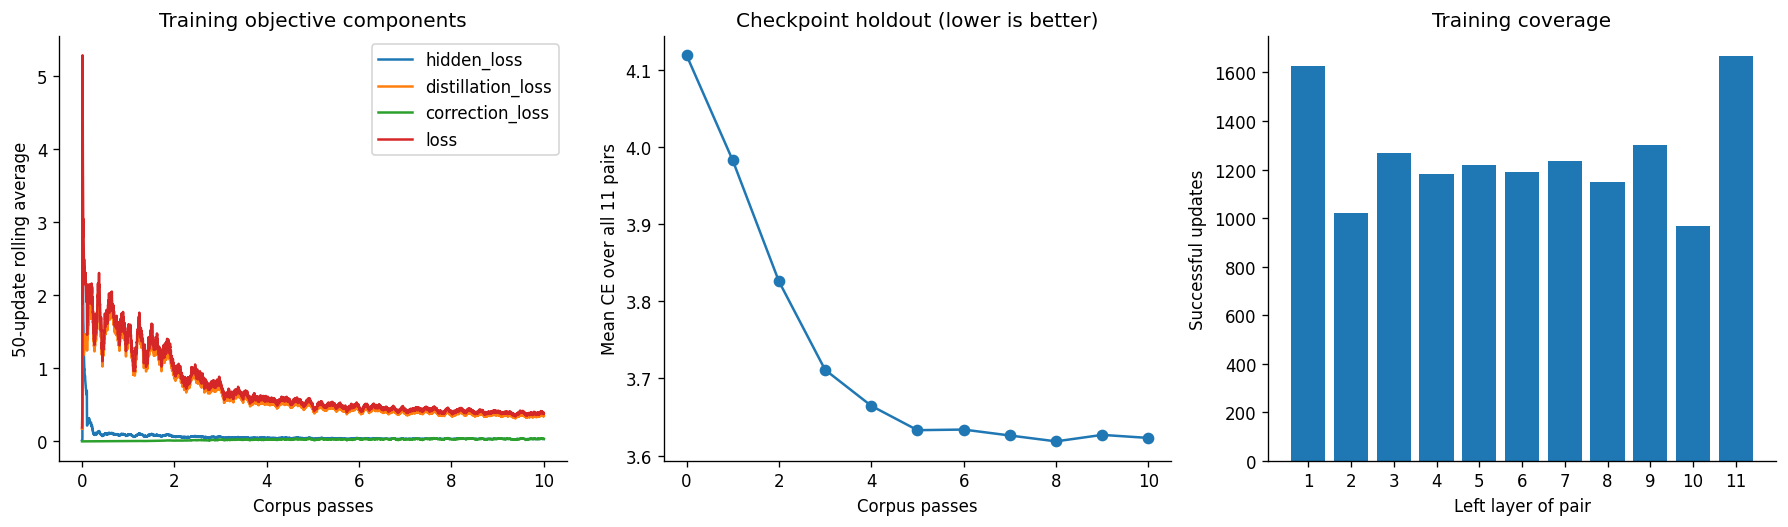

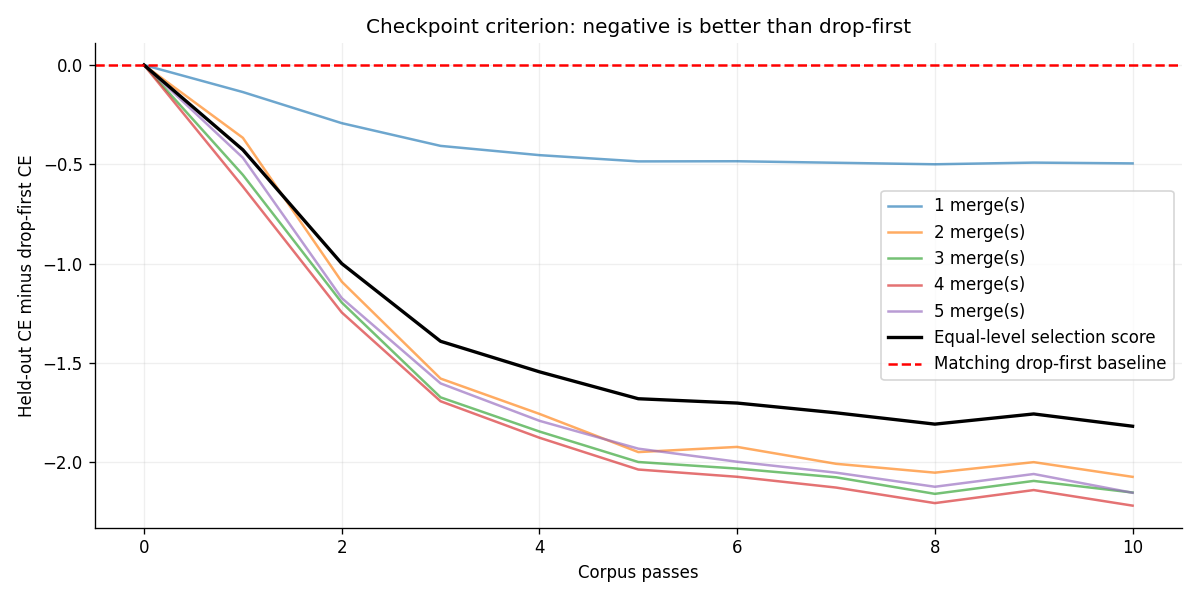

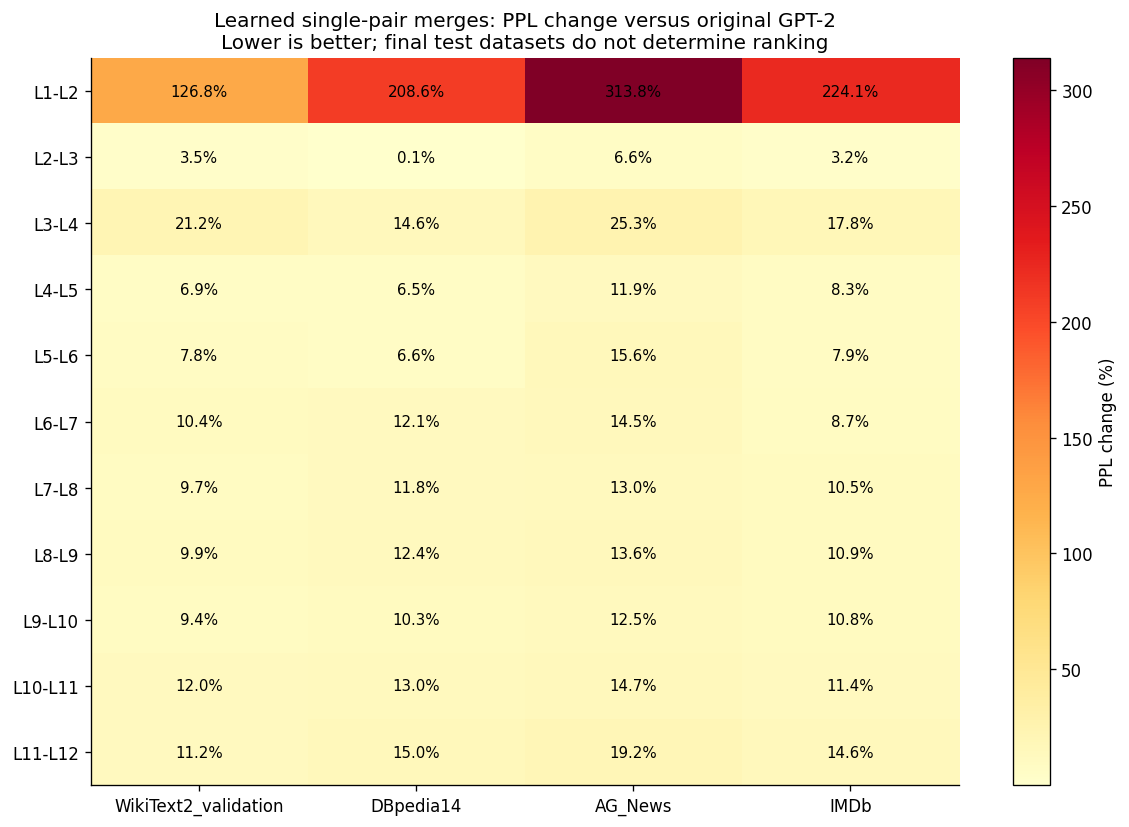

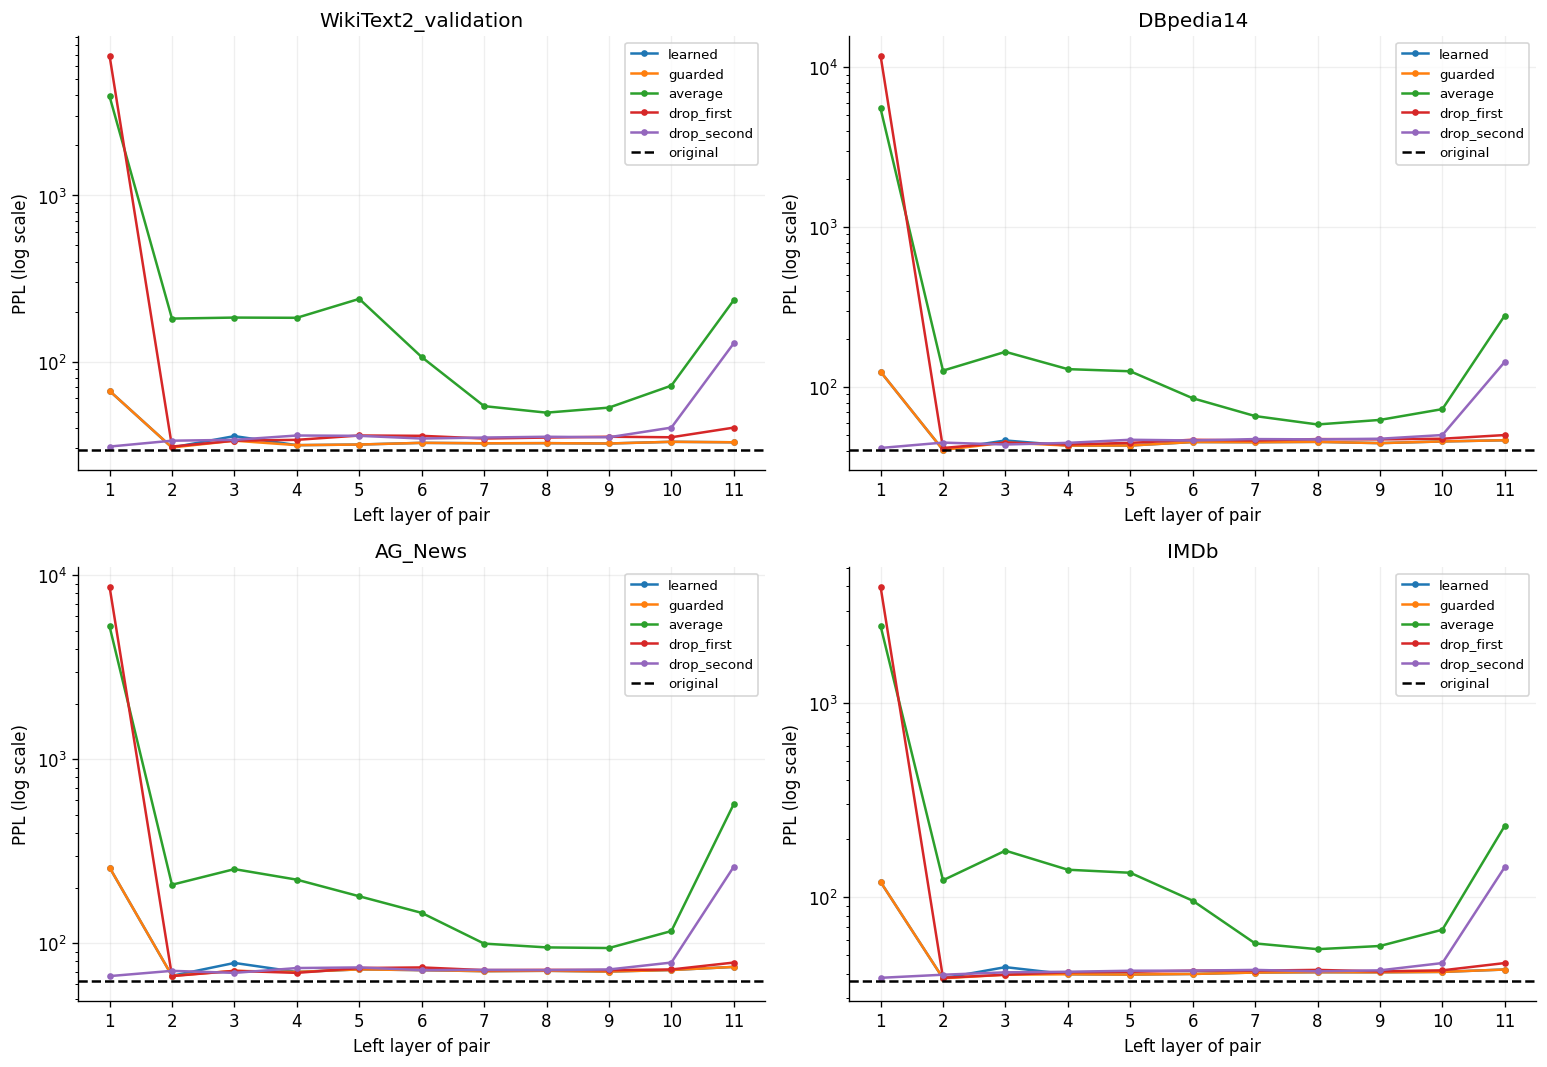

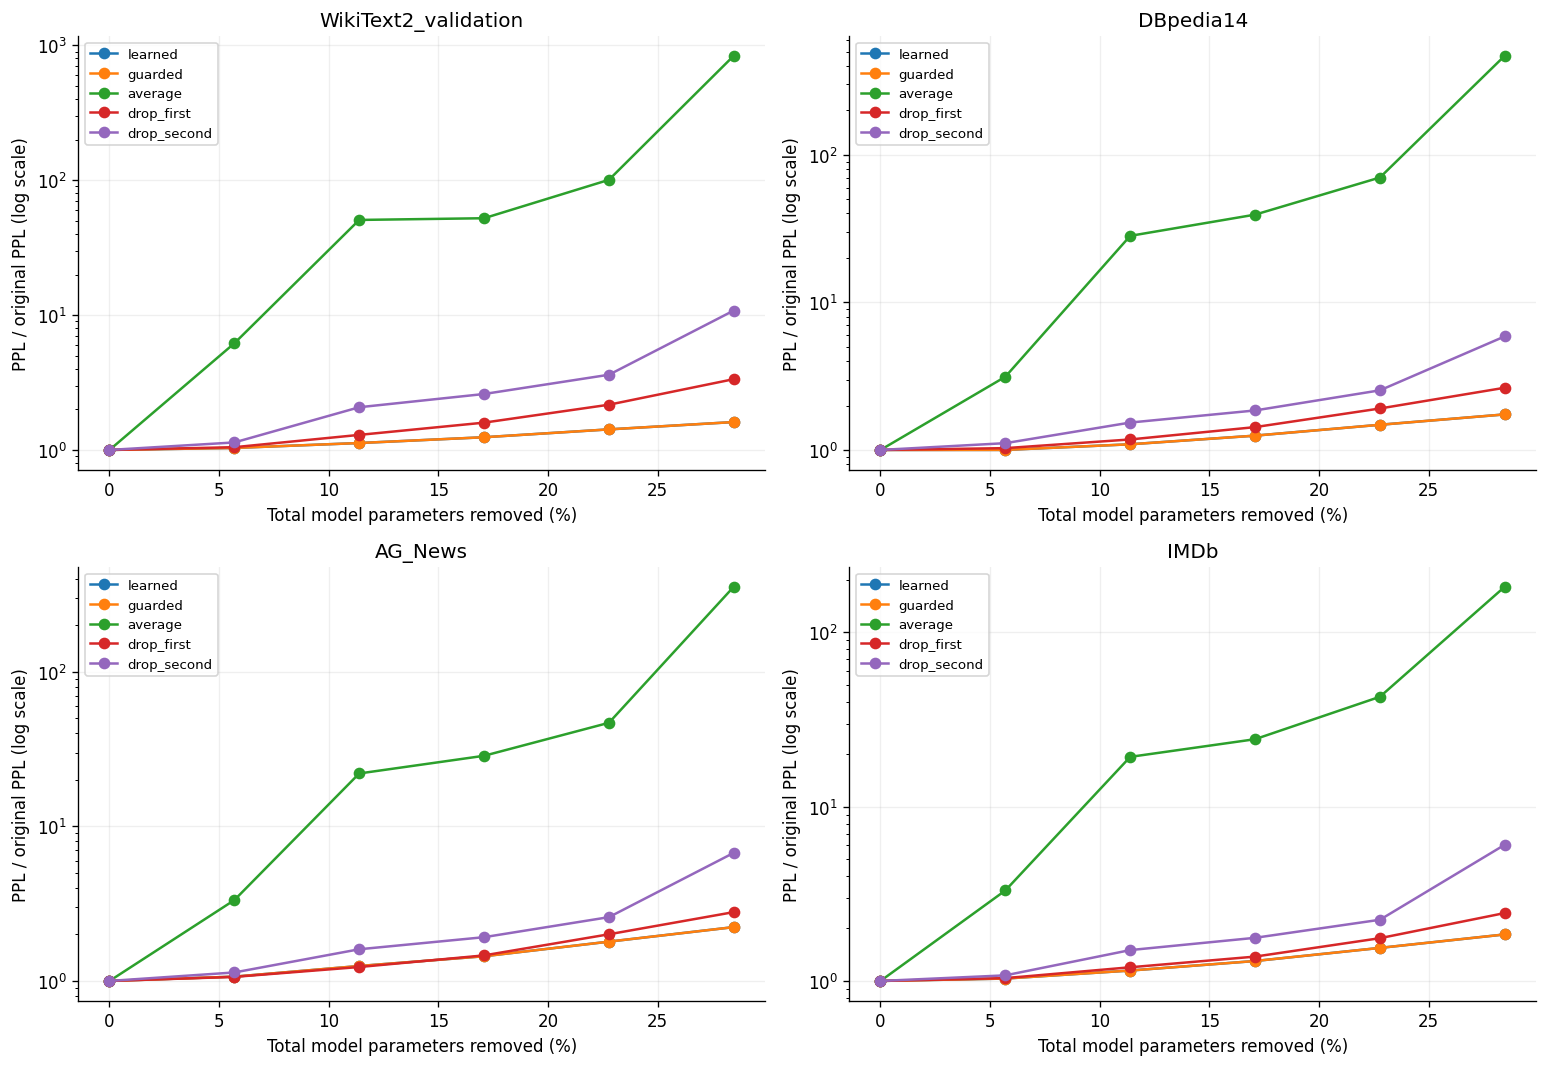

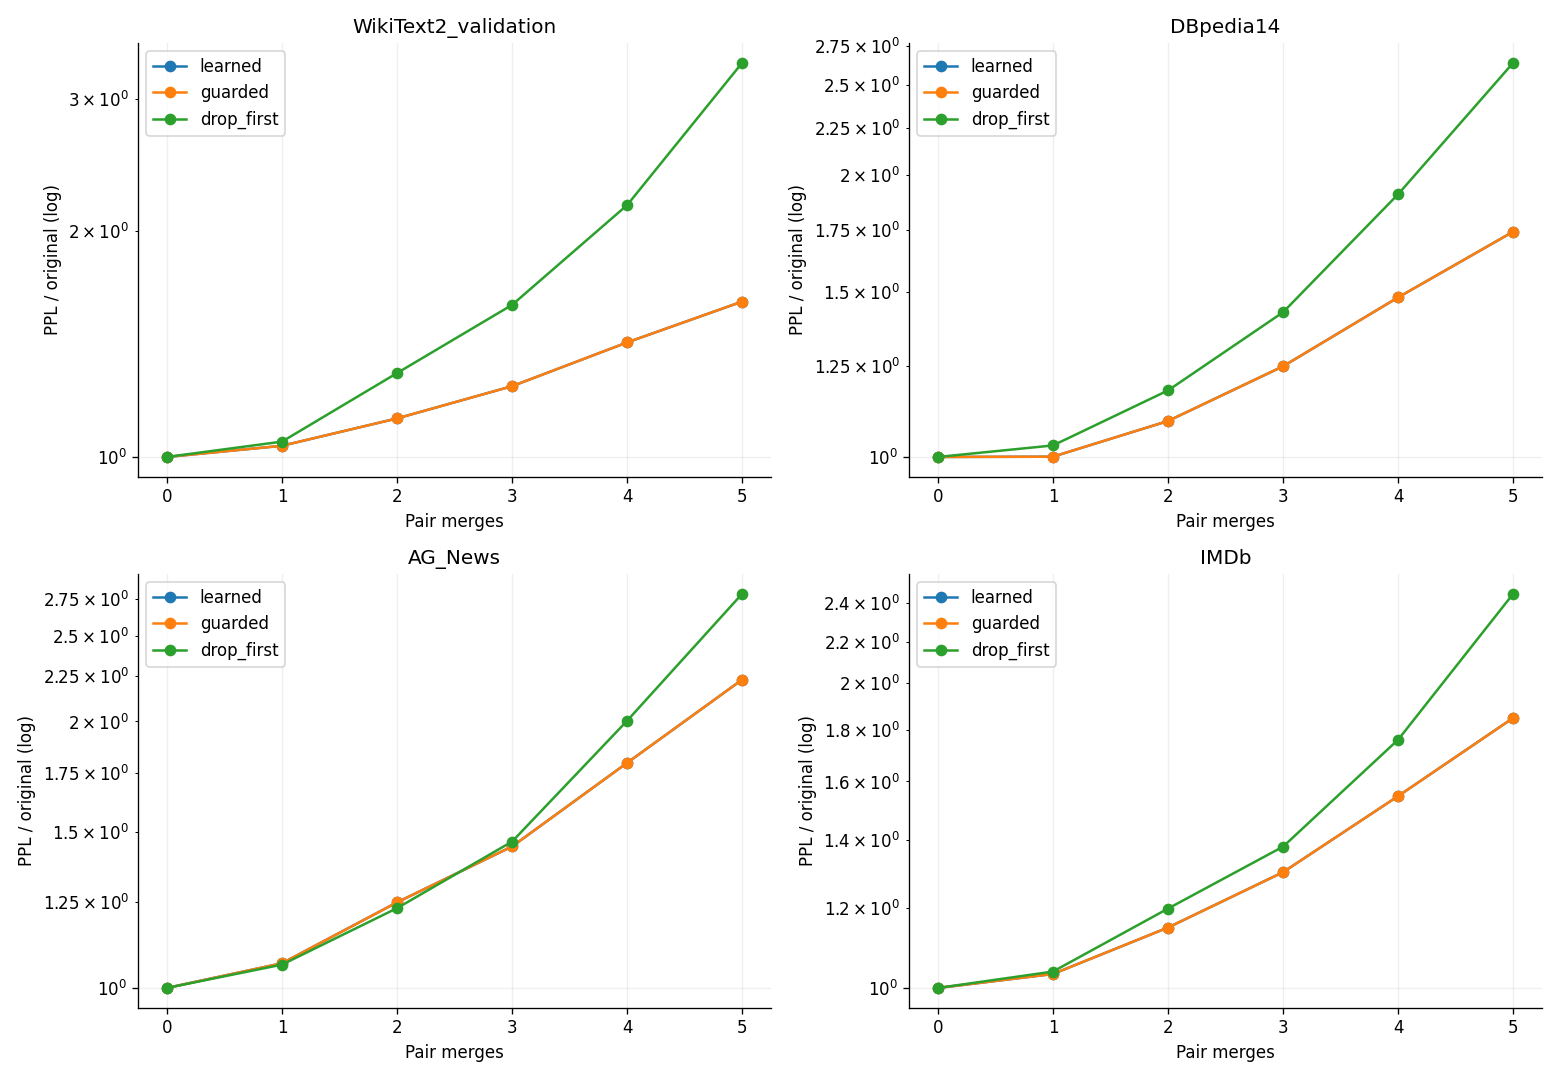

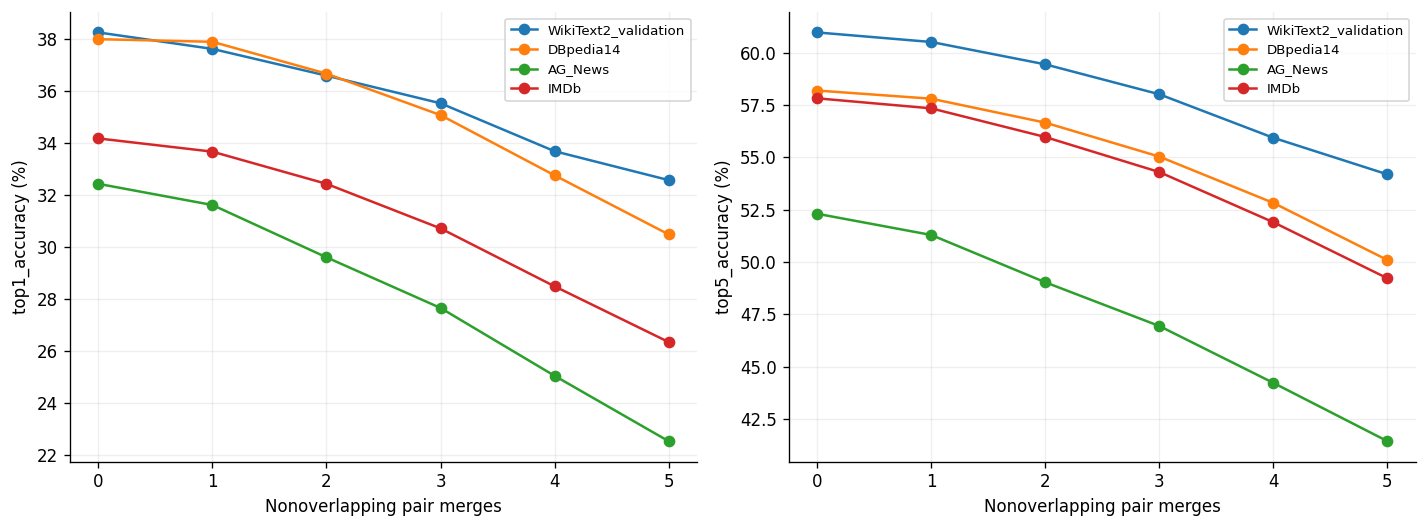

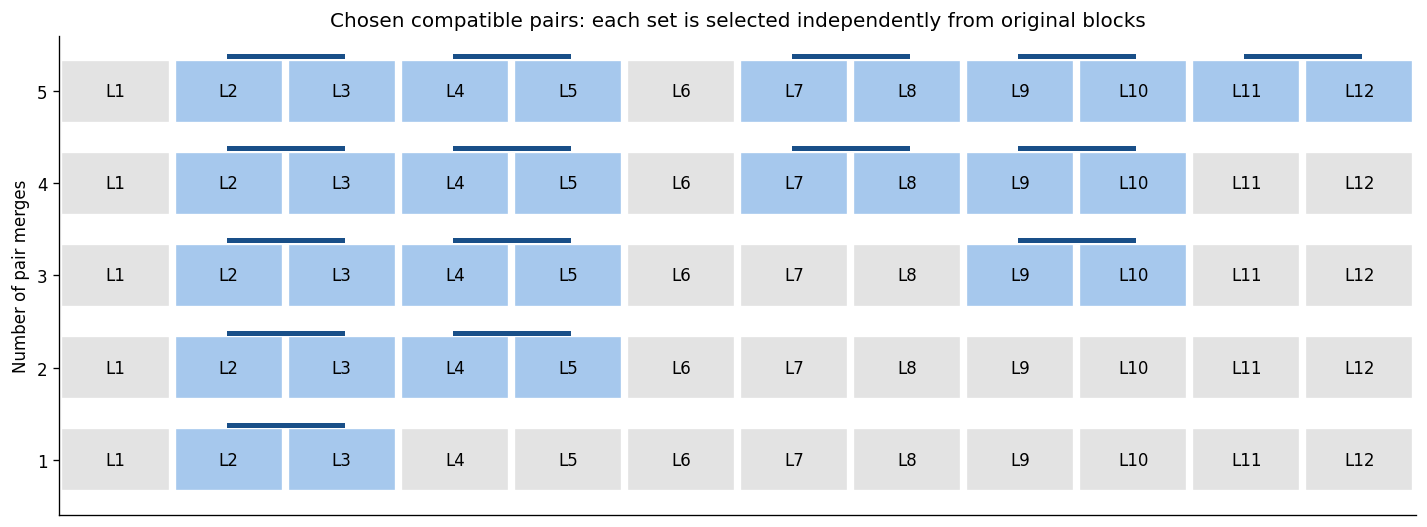

In [8]:
for filename in ["training_and_validation.png", "joint_checkpoint_selection.png", "single_pair_heatmap.png", "single_pairs_controls.png", "compression_quality_tradeoff.png", "guarded_vs_raw.png", "next_token_accuracy.png", "selected_pair_layout.png"]:
    path = experiment.out / "charts" / filename
    if path.exists():
        display(Image(filename=str(path)))


## Saving and resuming

Save the entire output folder before Kaggle discards the session. To resume, attach those saved outputs and copy the folder into the configured working path before constructing the experiment. Use only your trusted checkpoints. Do not copy old v5/v6 checkpoints into this run.

The measured global batch size is in `batch_benchmark.csv` and `training_complete.json`. The dual-GPU checks are in `gpu_preflight.json` and `dual_gpu_preflight.json`. Larger batches do not automatically improve convergence.

Client exports contain compressed GPT-2 and tokenizer only. Their `compression_manifest.json` records `effective_method`, acceptance scores and the original/merger hashes. If a learned plan is rejected, its raw test results remain visible; fallback is never presented as a learned improvement.

Authoring validation is offline. This revision has not been executed on a real dual-T4 system here. Runtime checks execute on Kaggle before optimization. Teacher matching follows [knowledge distillation](https://arxiv.org/abs/1503.02531); next-token scoring uses the [sliding-window principle](https://huggingface.co/docs/transformers/en/perplexity).
